# Семинар по теме «Ансамблевые методы: Bagging, Random Forest и их модификации»


В этом семинаре мы рассмотрим ключевые техники построения ансамблей: бэггинг, случайный лес, экстремально рандомизированные деревья (одна из версий случайного леса).

Ты узнаешь:

- как устроен бэггинг и чем он полезен;

- как работает случайный лес и в чём его отличие от бэггинга;

- как различные гиперпараметры влияют на качество бэггинга и леса;

- как использовать `oob_score` для оценки модели;

- как оценивать важность признаков;

- какие особенности есть у метода Isolation Forest для работы с выбросами.


<!-- Ансамблевые методы машинного обучения представляют собой подход, при котором несколько базовых моделей $b_i(x)$ объединяются в одну комплексную модель $a(x)$ для улучшения качества и надёжности прогнозов:

$$a(x) = b(b_1(x), b_2(x), ..., b_M(x))$$

,где $b_i$ – базовые алгоритмы (в одиночку слабые), а $b$ – мета-алгоритм, который как-то агрегирует предсказания $M$ слабых алгоритмов для того, чтобы получить сильный общий **ансамбль** $a(x)$.

Практическая ценность ансамблей обусловлена способностью компенсировать недостатки отдельных моделей. В случаях, когда одна модель слишком склонна к переобучению, другая может внести стабильность; если часть алгоритмов плохо работает на одном наборе признаков, другие — напротив, окажутся более эффективными. За счёт такого «коллективного интеллекта» ансамбли зачастую превосходят по точности и устойчивости любую из своих базовых моделей.

Ансамблевые методы находят широкое применение в самых разных областях — от рекомендаций фильмов и товаров (где комбинируются прогнозы разных алгоритмов) до финансового скоринга (где объединение моделей помогает надёжнее оценить риск невозврата кредита) и медицины (например, для более точного распознавания заболеваний по снимкам). В индустрии ансамбли часто используются в задачах прогнозирования спроса, обнаружения аномалий, распознавания речи и текста. Более того, на соревнованиях по машинному обучению, таких как Kaggle, ансамбли являются одним из основных инструментов команд, показывающих наилучшие результаты, поскольку они позволяют увеличить точность и устойчивость модели без радикального изменения архитектуры.

В ходе этого семинара мы рассмотрим ключевые техники построения ансамблей:

* Бэггинг (Bagging) — обучение множества моделей на разных бутстрэп-выборках и усреднение их предсказаний.

* Случайный лес (Random Forest) — расширение бэггинга с дополнительной рандомизацией признаков на каждом узле.

* Экстремально рандомизированные деревья (Extra Trees) — усиленная версия случайного леса с ещё большим рандомизированием порогов разбиений. -->

## Что такое ансамбли и где они применяются

Ансамблевые методы машинного обучения представляют собой подход, при котором несколько базовых моделей $b_i(x)$ объединяются в одну комплексную модель $a(x)$ для улучшения качества и надёжности прогнозов:

$$a(x) = b(b_1(x), b_2(x), ..., b_M(x)),$$

где $b_i$ — базовые алгоритмы (в одиночку слабые), а $b$ — метаалгоритм, который как-то агрегирует предсказания $M$ слабых алгоритмов для того, чтобы получить сильный общий **ансамбль** $a(x)$.

Практическая ценность ансамблей — в способности компенсировать недостатки отдельных моделей. Если одна модель слишком склонна к переобучению, другая может внести стабильность; если часть алгоритмов плохо работает на одном наборе признаков, другие, напротив, окажутся более эффективными. Благодаря такому «коллективному интеллекту» ансамбли часто превосходят по точности и устойчивости любую из своих базовых моделей.

Ансамблевые методы применяют в разных областях, например:
- рекомендации фильмов и товаров (где комбинируются прогнозы разных алгоритмов);
- финансовый скоринг (где объединение моделей помогает надёжнее оценить риск невозврата кредита);
- медицина (например, для более точного распознавания заболеваний по снимкам);
- прогнозирование спроса;
- обнаружение аномалий;
- распознавание речи и текста.

На соревнованиях по машинному обучению, таких как Kaggle, ансамбли — один из основных инструментов команд, показывающих наилучшие результаты, так как ансамбли позволяют увеличить точность и устойчивость модели без радикального изменения архитектуры.










## Данные

In [1]:
!pip install tqdm

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from tqdm.auto import tqdm
from time import time
from sklearn.metrics import f1_score, roc_auc_score

/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

Поработаем с набором погодных данных в разных регионах Австралии. Для этого используем датасет Rain in Australia.

В нём содержатся наблюдения по разным метеопараметрам (например, температура, влажность, ветер) и метки — они показывают, будет ли дождь на следующий день после текущего.

Цель — научиться прогнозировать `RainTomorrow` на основе других погодных признаков. Эта задача относится к бинарной классификации, и у неё есть практическое значение: прогноз осадков используется в сельском хозяйстве, логистике, планировании мероприятий и управлении ресурсами. Ошибки в прогнозе могут привести к экономическим потерям или срыву операций.

Используем ансамблевые методы. Они позволяют улучшить качество прогноза по сравнению с одиночными моделями за счёт объединения их сильных сторон и компенсации слабых.

Однако перед тем, как их обучить и применить, проведём разведочный анализ данных (EDA) и препроцессинг датасета.

In [5]:
url = "https://rattle.togaware.com/weatherAUS.csv"
df = pd.read_csv(url)

### Разведочный анализ данных (EDA)

In [6]:
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,1.0,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0.2,No


**Названия и значения признаков:**

`Location` — название города в Австралии;

`MinTemp` — минимальная температура в течение дня (градусы Цельсия);

`MaxTemp` — максимальная температура в течение дня (градусы Цельсия);

`Rainfall` — количество осадков за день (миллиметры);

`Evaporation` — испарение за день (миллиметры);

`Sunshine` — яркое солнечное освещение за день (часы);

`WindGusDir` — направление самого сильного порыва ветра в течение дня (16 точек компаса);

`WindGuSpeed` — скорость самого сильного порыва ветра в течение дня (километры в час);

`WindDir9am` — направление ветра за 10 минут до 9 часов утра (точки компаса);

`WindDir3pm` — направление ветра за 10 минут до 15 часов (точки компаса);

`WindSpeed9am` — скорость ветра за 10 минут до 9 часов утра (километры в час);

`WindSpeed3pm` — скорость ветра за 10 минут до 15 часов (километры в час);

`Humidity9am` — влажность воздуха в 9 часов утра (проценты);

`Humidity3pm` — влажность воздуха в 15 часов (проценты);

`Pressure9am` — атмосферное давление в 9 часов утра (гектопаскали);

`Pressure3pm` — атмосферное давление в 15 часов (гектопаскали);

`Cloud9am` — доля неба, покрытого облаками, в 9 часов утра (в восьмых долях);

`Cloud3pm` — доля неба, покрытого облаками, в 15 часов (в восьмых долях);

`Temp9am` — температура в 9 часов утра (градусы Цельсия);

`Temp3pm` — температура в 15 часов (градусы Цельсия);

`RainToday` — Yes, если сегодня был дождь; No, если дождя не было;

`RainTomorrow` — 1 (Yes), если завтра ожидается дождь; 0 (No), если дождь не ожидается.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 275410 entries, 0 to 275409
Data columns (total 24 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           275410 non-null  str    
 1   Location       275410 non-null  str    
 2   MinTemp        270732 non-null  float64
 3   MaxTemp        270779 non-null  float64
 4   Rainfall       267316 non-null  float64
 5   Evaporation    115284 non-null  float64
 6   Sunshine       104284 non-null  float64
 7   WindGustDir    254944 non-null  str    
 8   WindGustSpeed  255145 non-null  float64
 9   WindDir9am     253956 non-null  str    
 10  WindDir3pm     263004 non-null  str    
 11  WindSpeed9am   269462 non-null  float64
 12  WindSpeed3pm   264722 non-null  float64
 13  Humidity9am    269181 non-null  float64
 14  Humidity3pm    263949 non-null  float64
 15  Pressure9am    245025 non-null  float64
 16  Pressure3pm    245048 non-null  float64
 17  Cloud9am       148891 non-null  float64


In [8]:
df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RISK_MM
count,270732.000000,270779.000000,267316.000000,115284.000000,104284.000000,255145.000000,269462.000000,264722.000000,269181.000000,263949.000000,245025.000000,245048.000000,148891.000000,142702.000000,270776.000000,265428.000000,267317.000000
mean,12.095957,23.263862,2.339247,5.494241,7.629457,39.993329,14.051525,18.534191,69.077517,51.464196,1017.662168,1015.229618,4.778885,4.734510,16.938796,21.751525,2.339139
std,6.431503,7.135398,8.608060,4.137800,3.776220,13.500968,8.822554,8.676622,19.385832,21.026635,7.099420,7.054916,2.895941,2.770912,6.534544,7.000990,8.608022
min,-8.700000,-4.100000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,978.600000,972.000000,0.000000,0.000000,-6.200000,-5.100000,0.000000
25%,7.500000,18.000000,0.000000,2.800000,4.900000,31.000000,7.000000,13.000000,57.000000,36.000000,1012.900000,1010.400000,2.000000,2.000000,12.200000,16.700000,0.000000
50%,11.900000,22.700000,0.000000,4.800000,8.500000,39.000000,13.000000,17.000000,70.000000,52.000000,1017.600000,1015.200000,6.000000,5.000000,16.700000,21.200000,0.000000
75%,16.800000,28.200000,0.600000,7.400000,10.600000,48.000000,19.000000,24.000000,84.000000,66.000000,1022.500000,1020.100000,7.000000,7.000000,21.500000,26.500000,0.600000
max,33.900000,49.600000,474.000000,138.700000,14.500000,154.000000,87.000000,87.000000,100.000000,100.000000,1042.500000,1040.300000,9.000000,9.000000,41.000000,48.200000,474.000000


In [9]:
# Числовые столбцы
numeric = df.select_dtypes(include=['number']).columns
numeric

Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm',
       'Temp9am', 'Temp3pm', 'RISK_MM'],
      dtype='str')

In [10]:
def nice(ax, title):
    ax.set_title(title, fontsize=14, pad=12)
    ax.grid(alpha=0.25)

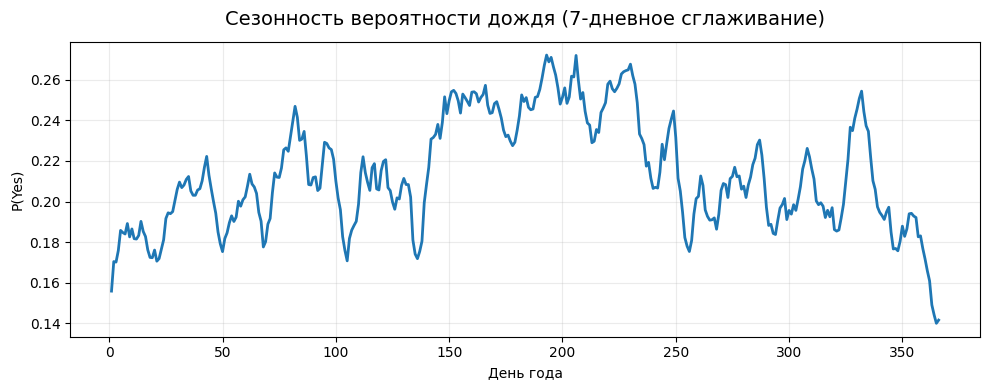

In [11]:
date = pd.to_datetime(df['Date'])
doy = date.dt.dayofyear
y = (df['RainTomorrow'] == 'Yes').astype(int)

p = y.groupby(doy).mean().rolling(7, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10,4))
ax.plot(p.index, p.values, lw=2)
ax.set_xlabel('День года'); ax.set_ylabel('P(Yes)')
nice(ax, 'Сезонность вероятности дождя (7-дневное сглаживание)')
plt.tight_layout(); plt.show()

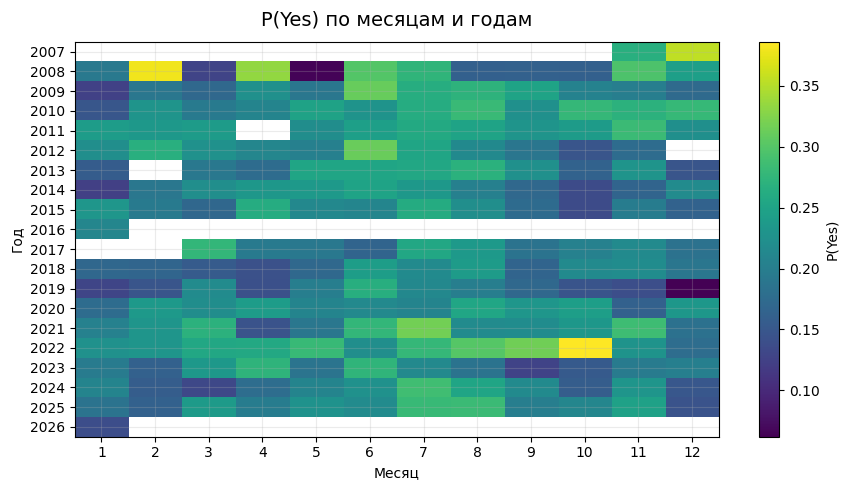

In [12]:
year = date.dt.year
month = date.dt.month
tab = y.groupby([year, month]).mean().unstack(level=1).sort_index()

fig, ax = plt.subplots(figsize=(9,5))
im = ax.imshow(tab.values, aspect='auto', interpolation='nearest')
ax.set_yticks(range(len(tab.index)), tab.index)
ax.set_xticks(range(12), np.arange(1,13))
ax.set_xlabel('Месяц'); ax.set_ylabel('Год')
nice(ax, 'P(Yes) по месяцам и годам')
fig.colorbar(im, ax=ax, label='P(Yes)')
plt.tight_layout(); plt.show()

/var/folders/gb/zxvw0tz51235z0btp3pngp3h0000gn/T/ipykernel_14849/297166402.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  tot = month_counts.sum(1)


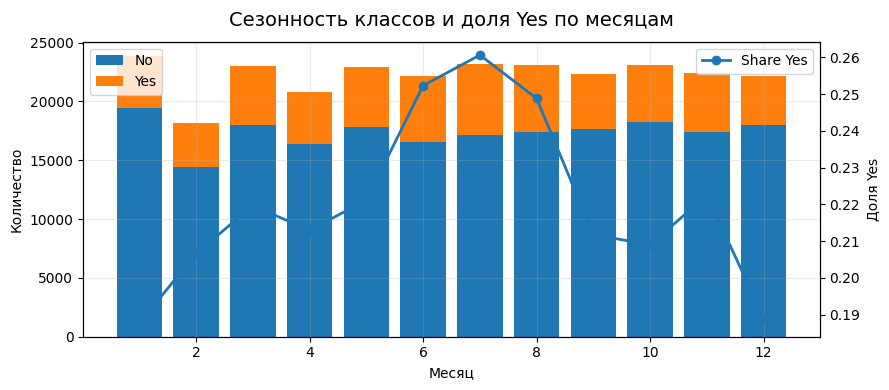

In [13]:
month_counts = df.groupby(month)['RainTomorrow'].value_counts().unstack(fill_value=0)
tot = month_counts.sum(1)
share_yes = month_counts.get('Yes', pd.Series(0, index=tot.index)) / tot

fig, ax = plt.subplots(figsize=(9,4))
ax.bar(month_counts.index, month_counts.get('No',0), label='No')
ax.bar(month_counts.index, month_counts.get('Yes',0),
       bottom=month_counts.get('No',0), label='Yes')
ax.set_xlabel('Месяц'); ax.set_ylabel('Количество'); ax.legend(loc='upper left')

ax2 = ax.twinx()
ax2.plot(share_yes.index, share_yes.values, marker='o', lw=2, label='Share Yes')
ax2.set_ylabel('Доля Yes')
ax2.legend(loc='upper right')
nice(ax, 'Сезонность классов и доля Yes по месяцам')
plt.tight_layout(); plt.show()

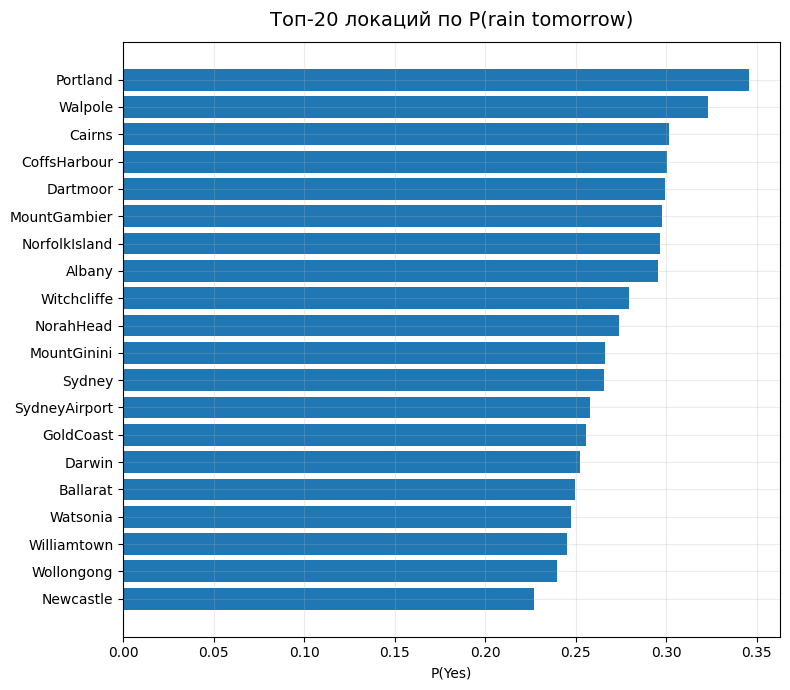

In [14]:
loc_rate = y.groupby(df['Location']).mean().sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(8,7))
ax.barh(loc_rate.index[::-1], loc_rate.values[::-1])
ax.set_xlabel('P(Yes)')
nice(ax, 'Топ-20 локаций по P(rain tomorrow)')
plt.tight_layout(); plt.show()

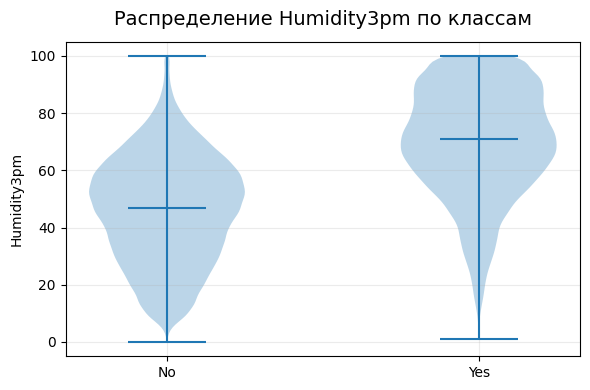

In [15]:
h3 = df[['Humidity3pm','RainTomorrow']].dropna()
data_no = h3.loc[h3['RainTomorrow']=='No','Humidity3pm'].values
data_yes = h3.loc[h3['RainTomorrow']=='Yes','Humidity3pm'].values

fig, ax = plt.subplots(figsize=(6,4))
ax.violinplot([data_no, data_yes], showmedians=True)
ax.set_xticks([1,2], ['No','Yes'])
ax.set_ylabel('Humidity3pm')
nice(ax, 'Распределение Humidity3pm по классам')
plt.tight_layout(); plt.show()

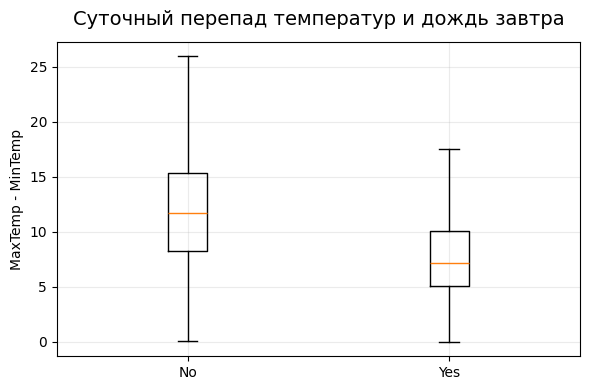

In [16]:
mxt = df['MaxTemp']; mnt = df['MinTemp']; rt = df['RainTomorrow']
mask = mxt.notna() & mnt.notna() & rt.notna()

delta_no = (mxt[mask]-mnt[mask])[rt[mask]=='No']
delta_yes = (mxt[mask]-mnt[mask])[rt[mask]=='Yes']

fig, ax = plt.subplots(figsize=(6,4))
ax.boxplot([delta_no.values, delta_yes.values], tick_labels=['No','Yes'], showfliers=False)
ax.set_ylabel('MaxTemp - MinTemp')
nice(ax, 'Суточный перепад температур и дождь завтра')
plt.tight_layout(); plt.show()

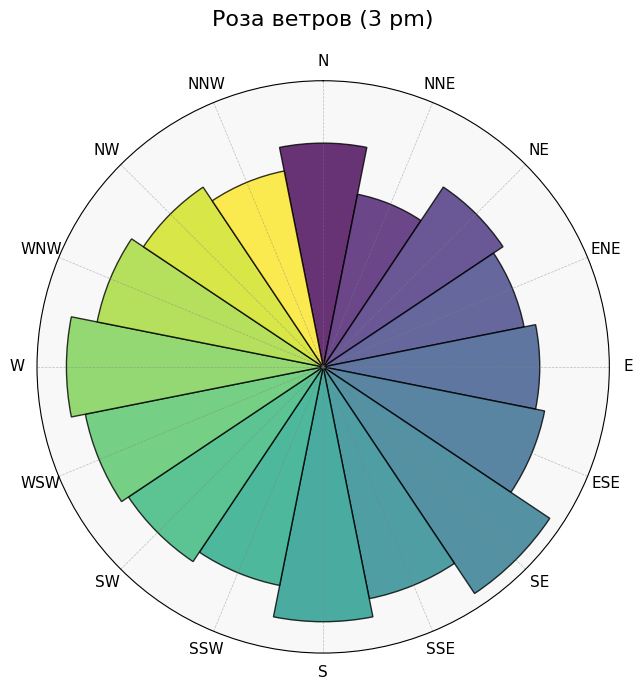

In [17]:
wd = df['WindDir3pm'].dropna()
compass = ['N','NNE','NE','ENE','E','ESE','SE','SSE',
           'S','SSW','SW','WSW','W','WNW','NW','NNW']
cnt = wd.value_counts().reindex(compass).fillna(0).values
theta = np.linspace(0, 2*np.pi, len(compass), endpoint=False)

# Цвета (градиент)
colors = plt.cm.viridis(np.linspace(0, 1, len(compass)))

fig = plt.figure(figsize=(7,7))
ax = plt.subplot(111, projection='polar')

bars = ax.bar(theta, cnt, width=2*np.pi/len(compass), align='center',
              color=colors, edgecolor='black', alpha=0.8)

# Настройка внешнего вида
ax.set_xticks(theta, compass, fontsize=11)
ax.set_yticks([])  # Убираем круговые подписи
ax.set_facecolor('#f8f8f8')
ax.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
ax.set_theta_zero_location("N")  # 0° = север
ax.set_theta_direction(-1)       # Направление по часовой стрелке

ax.set_title('Роза ветров (3 pm)', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

Посмотрим на распределения категориальных признаков.

/var/folders/gb/zxvw0tz51235z0btp3pngp3h0000gn/T/ipykernel_14849/2778227674.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = [c for c in df.select_dtypes(include=['object', 'category']).columns


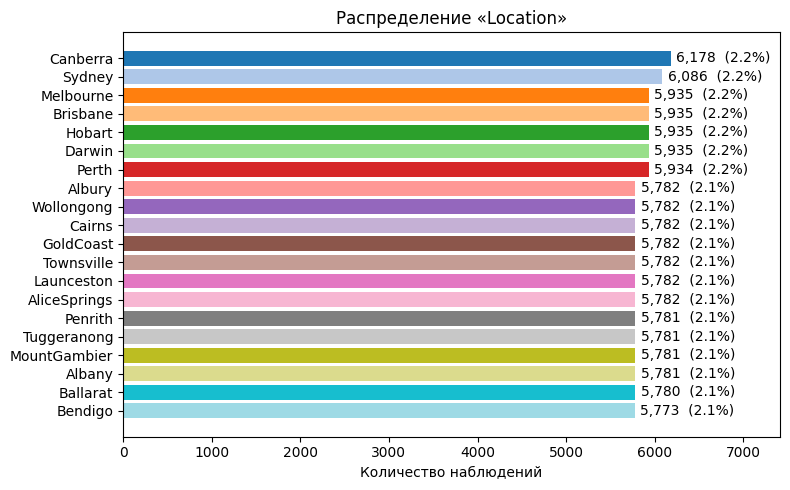

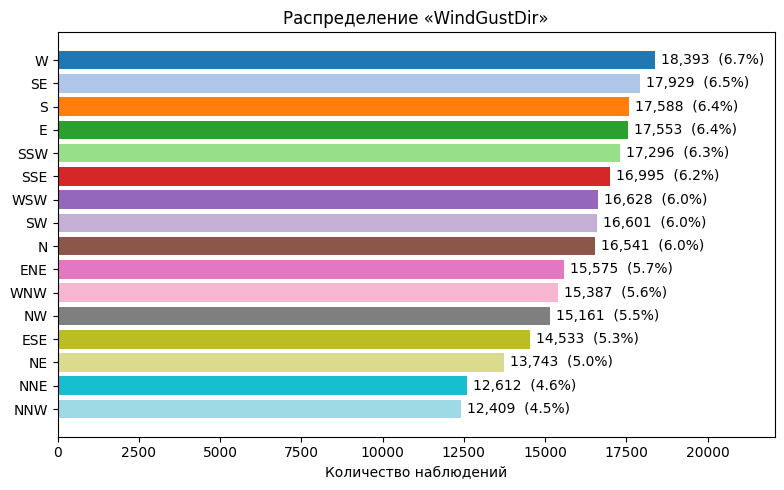

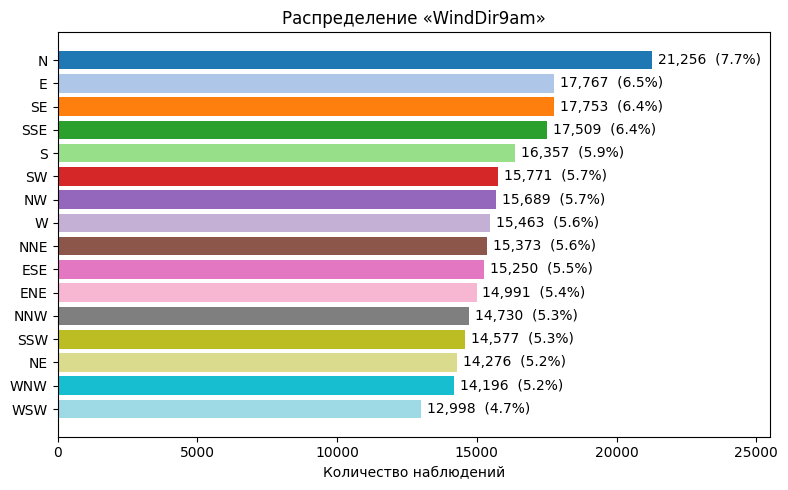

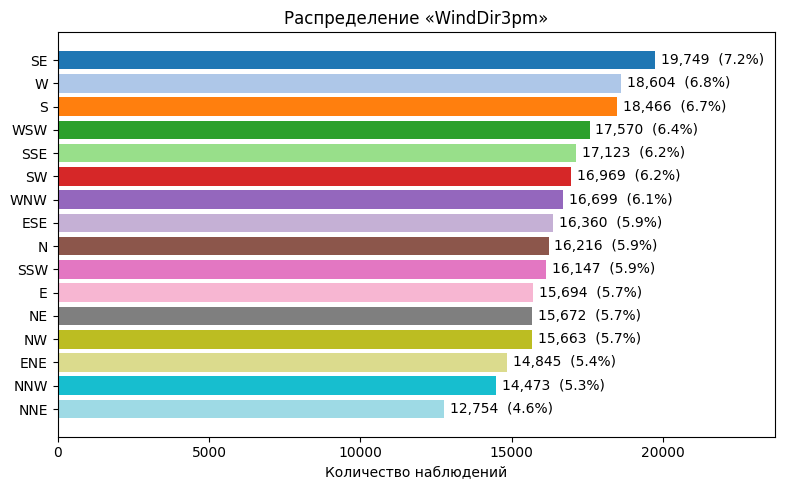

In [18]:
from matplotlib.colors import to_hex

exclude = {'Date', 'RainToday', 'RainTomorrow'}
cat_cols = [c for c in df.select_dtypes(include=['object', 'category']).columns
            if c not in exclude]

TOP_N = 20

for col in cat_cols:
    counts = df[col].value_counts().head(TOP_N)
    total = len(df)

    # Современный способ получения колормэп
    cmap = plt.get_cmap('tab20')
    colors = [to_hex(cmap(x)) for x in np.linspace(0, 1, len(counts))]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.margins(x=0.2)
    ax.barh(counts.index.astype(str), counts.values, color=colors)
    ax.set_title(f'Распределение «{col}»')
    ax.set_xlabel('Количество наблюдений')
    ax.invert_yaxis()

    for i, (label, val) in enumerate(counts.items()):
        ax.text(val + max(counts.values)*0.01,
                i,
                f'{val:,}  ({val/total:.1%})',
                va='center')

    plt.tight_layout()
    plt.show()

Корреляции помогут выявить сильносвязанные признаки, которые могут негативно влиять на ансамбли.

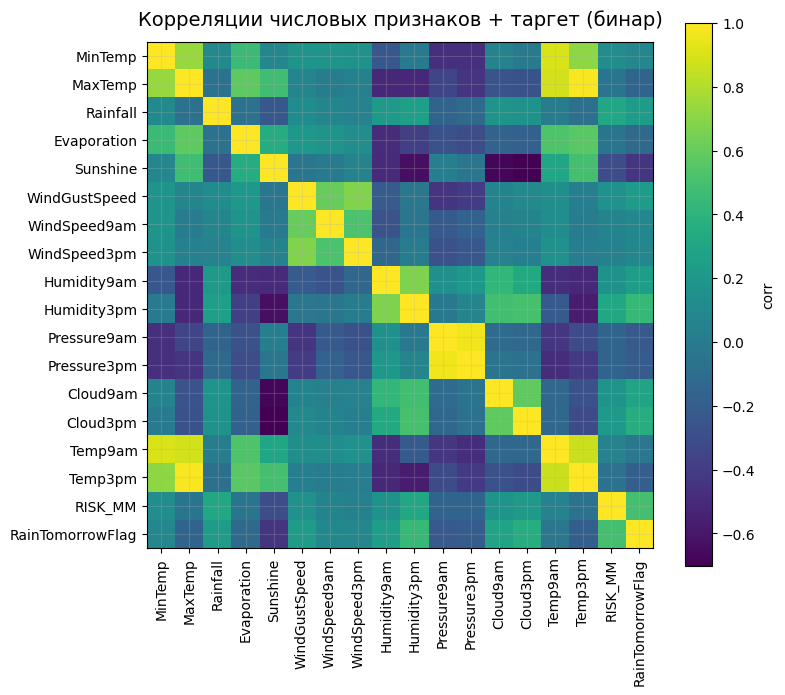

In [19]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
rt_flag = (df['RainTomorrow'] == 'Yes').astype(int)
corr = pd.concat([df[num_cols], rt_flag.rename('RainTomorrowFlag')], axis=1).corr()

fig, ax = plt.subplots(figsize=(8,7))
im = ax.imshow(corr.values, interpolation='nearest')
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
nice(ax, 'Корреляции числовых признаков + таргет (бинар)')
fig.colorbar(im, ax=ax, label='corr')
plt.tight_layout(); plt.show()

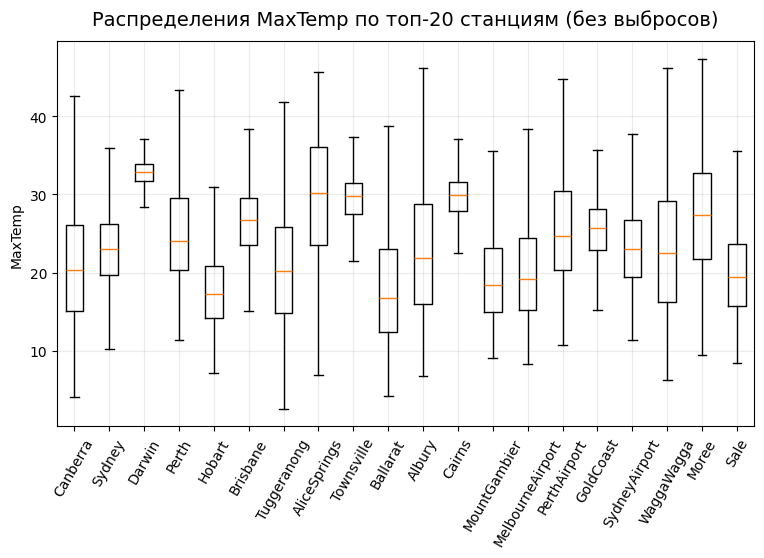

In [20]:
t = (df.groupby('Location')['MaxTemp']
       .agg(['median','quantile'])
       .rename(columns={'quantile':'q'})
    )
# Перерисуем вручную ящики (альтернатива: boxplot by group, но много категорий)
sub = df[['Location','MaxTemp']].dropna()
top = sub['Location'].value_counts().head(20).index
vals = [sub.loc[sub['Location']==loc, 'MaxTemp'].values for loc in top]

fig, ax = plt.subplots(figsize=(9,5))
ax.boxplot(vals, tick_labels=top, showfliers=False)
ax.set_ylabel('MaxTemp'); ax.tick_params(axis='x', rotation=60)
nice(ax, 'Распределения MaxTemp по топ-20 станциям (без выбросов)')

### Препроцессинг

Столбец `RISK_MM` содержит информацию о количестве осадков, которые выпадут на следующий день. Очевидно, что этот признак приведёт к data leakage, поэтому удалим его.

Затем удаляем строки, в которых нет метки `RainToday` или `RainTomorrow`, поскольку без них нельзя обучаться или оценивать модель.

In [21]:
df.drop(['RISK_MM'], axis=1, inplace=True)

In [22]:
df.dropna(subset=['RainToday','RainTomorrow'], axis=0, inplace=True)

Выведем, сколько фичей и объектов осталось в датасете.

In [23]:
print(f"Форма датасета: {df.shape}")

Форма датасета: (264742, 23)


In [24]:
df.info()

<class 'pandas.DataFrame'>
Index: 264742 entries, 0 to 275409
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           264742 non-null  str    
 1   Location       264742 non-null  str    
 2   MinTemp        263736 non-null  float64
 3   MaxTemp        263796 non-null  float64
 4   Rainfall       264742 non-null  float64
 5   Evaporation    113311 non-null  float64
 6   Sunshine       102341 non-null  float64
 7   WindGustDir    247029 non-null  str    
 8   WindGustSpeed  247217 non-null  float64
 9   WindDir9am     244973 non-null  str    
 10  WindDir3pm     253481 non-null  str    
 11  WindSpeed9am   260036 non-null  float64
 12  WindSpeed3pm   255141 non-null  float64
 13  Humidity9am    262260 non-null  float64
 14  Humidity3pm    256922 non-null  float64
 15  Pressure9am    236306 non-null  float64
 16  Pressure3pm    236242 non-null  float64
 17  Cloud9am       146244 non-null  float64
 18  

В датасете достаточно много пропущенных значений, причём почти все признаки обладают определённой долей NA-значений. Посмотрим, в каких признаках доля пропущенных наблюдений наибольшая.

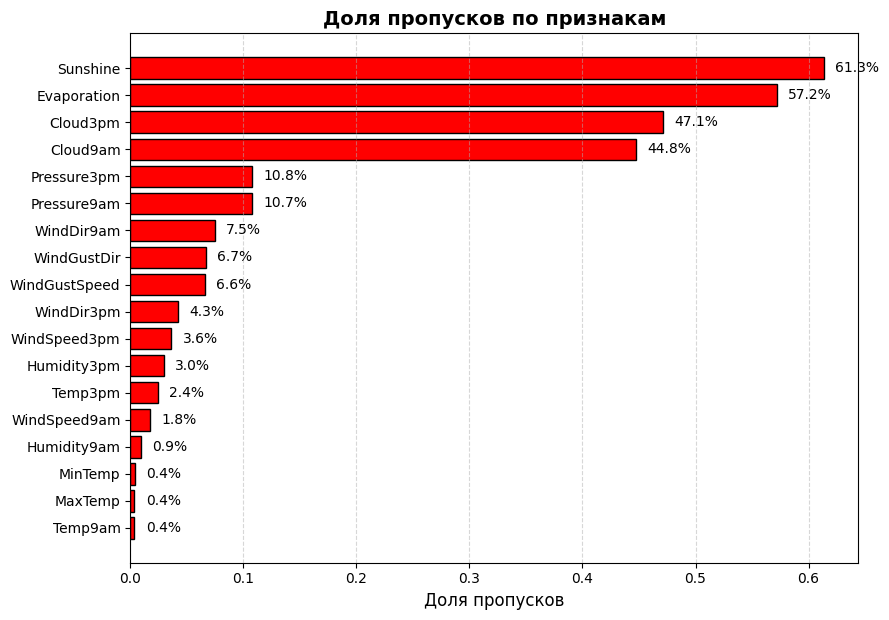

In [25]:
# Получаем серию для визуализации
na_ratio = df.isnull().mean()
na_features = na_ratio[na_ratio > 0].sort_values(ascending=True)  # Снизу вверх — от меньшего к большему

plt.figure(figsize=(9, max(3, 0.35 * len(na_features))))
bars = plt.barh(na_features.index, na_features.values, color="r", edgecolor="black")

# Ставим подписи процентов справа от столбцов
for num, bar in enumerate(bars):
    width = bar.get_width()
    plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f"{width:.1%}", va='center', fontsize=10)

plt.xlabel("Доля пропусков", fontsize=12)
plt.title("Доля пропусков по признакам", fontsize=14, fontweight='bold')
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Графическая тепловая карта отражает расположение пропусков. Можно быстро обнаружить столбцы с массовыми пропусками или «полосы» пропусков в датасете.

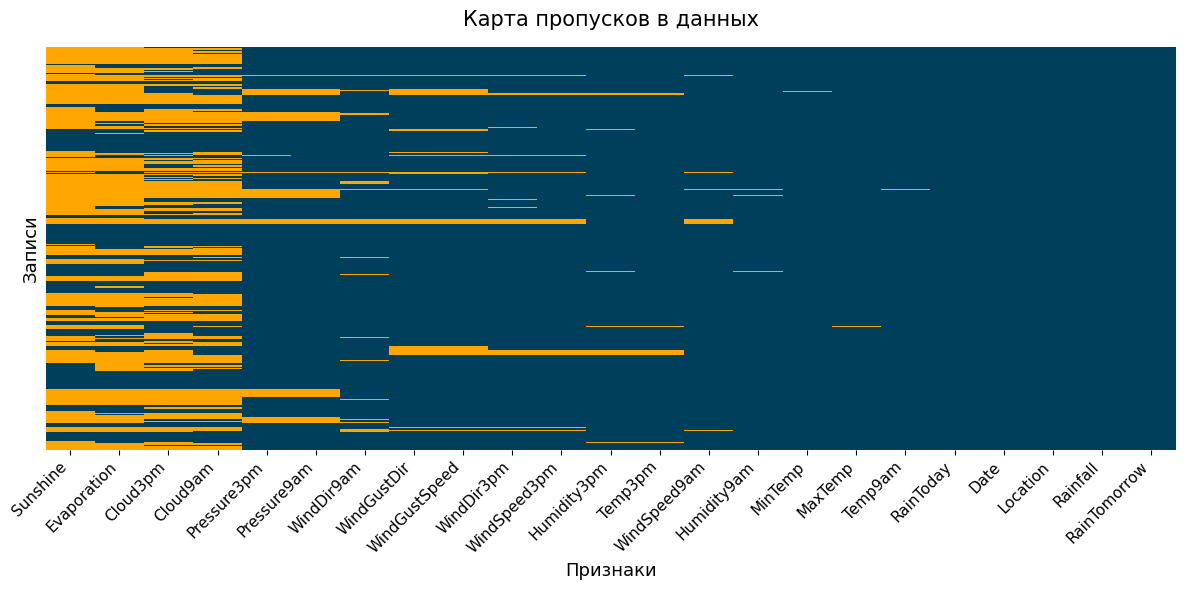

In [26]:
# Сортируем колонки по доле NaN (сначала больше пропусков)
nan_order = df.isna().mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12,6))
sns.heatmap(
    df[nan_order].isnull(),
    cmap=['#003f5c', '#ffa600'],  # Тёмно-синий означает «есть данные», жёлтый — пропуск
    cbar=False,
    yticklabels=False,
    ax=ax
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=11)
ax.set_xlabel('Признаки', fontsize=13)
ax.set_ylabel('Записи', fontsize=13)
ax.set_title('Карта пропусков в данных', fontsize=15, pad=15)
plt.tight_layout()
plt.show()

Посчитаем суммарно, сколько пропусков во всём датасете.

In [27]:
df.isnull().sum().sum()

np.int64(714070)

NA-значения нежелательны — нужно заполнить отсутствующие данные.

Для этого разобьём признаки на числовые и категориальные. Для числовых признаков заполним NAs средним значением по каждому признаку и региону Австралии. Для категориальных фичей сделаем то же самое, но используем моду.

Если в регионе нет данных по признаку, заполним их средними (или модой) по всем регионам.

In [28]:
# 1. Списки колонок
numeric_cols = (
    df
    .select_dtypes(include=['int64','float64'])
    .columns
    .difference(['RainToday','RainTomorrow'])
    .tolist()
)
cat_cols = (
    df
    .select_dtypes(include=['object','category'])
    .columns
    .difference(['Location','Date','RainToday','RainTomorrow'])
    .tolist()
)

# 2. Заполняем пропуски средним/модой внутри каждой группы Location
df[numeric_cols] = df.groupby('Location')[numeric_cols].transform(lambda x: x.fillna(x.mean()))

df[cat_cols] = df.groupby('Location')[cat_cols].transform(lambda x: x.fillna(x.mode().iloc[0]))

# 3. Дозаполняем остаточные NaN глобальными mean/mode
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())
df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])

/var/folders/gb/zxvw0tz51235z0btp3pngp3h0000gn/T/ipykernel_14849/4248170163.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  .select_dtypes(include=['object','category'])


Проверим, избавились ли мы от всех пропусков.

In [29]:
df.isnull().sum().sum()

np.int64(0)

In [30]:
# Выводим быстрые статистики
df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,264742.000000,264742.00000,264742.000000,264742.000000,264742.000000,264742.000000,264742.000000,264742.000000,264742.000000,264742.000000,264742.000000,264742.000000,264742.000000,264742.000000,264742.000000,264742.000000
mean,12.092172,23.27726,2.329311,5.517883,7.647237,39.986694,14.030433,18.536527,69.069140,51.634066,1017.692566,1015.289466,4.881357,4.801126,16.926924,21.750290
std,6.422224,7.11516,8.555288,2.851955,2.393369,13.054897,8.750931,8.560200,19.318702,20.814276,6.719296,6.659979,2.203805,2.047012,6.530643,6.955137
min,-8.700000,-4.10000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,978.600000,972.000000,0.000000,0.000000,-6.200000,-5.100000
25%,7.500000,18.00000,0.000000,3.904834,7.200000,31.000000,7.000000,13.000000,57.000000,37.000000,1013.600000,1011.100000,4.000000,4.030442,12.200000,16.800000
50%,11.900000,22.70000,0.000000,5.517883,7.647237,39.000000,13.000000,19.000000,70.000000,52.000000,1017.692566,1015.289466,4.881357,4.801126,16.700000,21.200000
75%,16.700000,28.20000,0.600000,6.166667,8.600000,46.000000,19.000000,24.000000,83.000000,66.000000,1021.900000,1019.500000,6.521889,6.000000,21.500000,26.400000
max,33.900000,49.60000,474.000000,138.700000,14.500000,154.000000,87.000000,87.000000,100.000000,100.000000,1042.500000,1040.300000,9.000000,9.000000,41.000000,48.200000


In [31]:
df.head(3)

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,5.517883,7.647237,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.000000,5.244856,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,5.517883,7.647237,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,6.237944,5.244856,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,5.517883,7.647237,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,6.237944,2.000000,21.0,23.2,No,No


Информация о времени года и о самом годе может влиять на способность качественно предсказывать погодные условия (вероятность дождя).

Используем признак `Date`, чтобы создать две новые фичи — `Season` и `Year`.

In [32]:
# 1. Приводим к datetime
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')

# 2. Извлекаем год
df['Year'] = df['Date'].dt.year

# 3. Функция для определения сезона (южное полушарие)
def month_to_season(month):
    if month in (12, 1, 2):
        return 'Summer'
    elif month in (3, 4, 5):
        return 'Autumn'
    elif month in (6, 7, 8):
        return 'Winter'
    else:
        return 'Spring'

# 4. Применяем к номеру месяца
df['Season'] = df['Date'].dt.month.map(month_to_season)

In [33]:
df.head(3)

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Year,Season
0,2008-12-01,Albury,13.4,22.9,0.6,5.517883,7.647237,W,44.0,W,...,1007.7,1007.1,8.000000,5.244856,16.9,21.8,No,No,2008,Summer
1,2008-12-02,Albury,7.4,25.1,0.0,5.517883,7.647237,WNW,44.0,NNW,...,1010.6,1007.8,6.237944,5.244856,17.2,24.3,No,No,2008,Summer
2,2008-12-03,Albury,12.9,25.7,0.0,5.517883,7.647237,WSW,46.0,W,...,1007.6,1008.7,6.237944,2.000000,21.0,23.2,No,No,2008,Summer


Теперь `Date` можно удалить.

In [34]:
df.drop(columns = 'Date',inplace=True)

У нас есть все признаки, с которыми будем работать.

Преобразуем категориальные переменные в бинарные 1/0 с помощью функции `pandas.get_dummies()`.

In [35]:
df = pd.get_dummies(df, dtype=int, drop_first=True)
df.head(3)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,RainToday_Yes,RainTomorrow_Yes,Season_Spring,Season_Summer,Season_Winter
0,13.4,22.9,0.6,5.517883,7.647237,44.0,20.0,24.0,71.0,22.0,...,0,0,0,1,0,0,0,0,1,0
1,7.4,25.1,0.0,5.517883,7.647237,44.0,4.0,22.0,44.0,25.0,...,0,0,0,0,1,0,0,0,1,0
2,12.9,25.7,0.0,5.517883,7.647237,46.0,19.0,26.0,38.0,30.0,...,0,0,0,0,1,0,0,0,1,0


In [36]:
df.shape

(264742, 115)

In [37]:
y = df['RainTomorrow_Yes']

Посмотрим, как распределена целевая переменная и есть ли значительный дисбаланс классов.

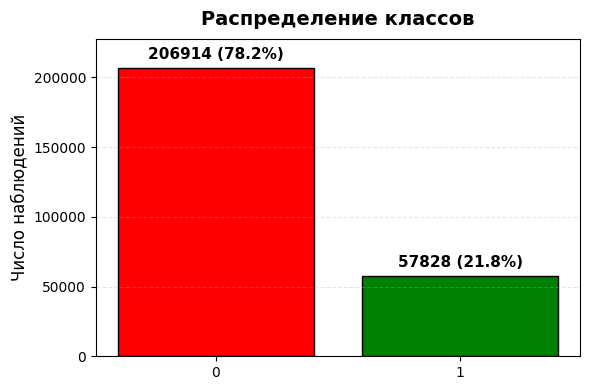

In [38]:
# 1. Считаем количество и доли каждого класса
counts = y.value_counts(dropna=False)
percentages = (counts / len(y)) * 100

# 2. Строим barplot
plt.figure(figsize=(6, 4))

# Цвета для каждого столбца
colors = ['r', 'g', 'b']
bars = plt.bar(counts.index.astype(str), counts.values, color=colors, edgecolor='black')

plt.title("Распределение классов", fontsize=14, fontweight='bold', pad=10)
plt.xlabel("")
plt.ylabel("Число наблюдений", fontsize=12)

# Добавляем подписи над каждым столбцом
max_count = counts.max()
for bar in bars:
    height = bar.get_height()
    label = f"{int(height)} ({height / len(y) * 100:.1f}%)"
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + max_count * 0.02,  # Чуть выше самого высокого столбца
        label,
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

plt.ylim(0, max_count * 1.10)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Разделим данные на train- и test-выборки. Мы убедились, что есть дисбаланс классов в таргете, поэтому используем гиперпараметр `stratify`.

In [39]:
df.rename({'RainToday_Yes':'RainToday','RainTomorrow_Yes':'RainTomorrow'},axis=1,inplace=True)

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns=['RainTomorrow']), df['RainTomorrow'],
    test_size=0.3, random_state=42, stratify=df['RainTomorrow'])

Многие алгоритмы и визуализации работают лучше, когда признаки центрированы и приведены к единичной дисперсии.

Применим `StandardScaler` ко всем числовым колонкам.

In [41]:
# Числовые столбцы
numeric = numeric.drop('RISK_MM')
numeric

Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm',
       'Temp9am', 'Temp3pm'],
      dtype='str')

In [42]:
# Инициализируем скейлер
scaler = StandardScaler()

# Fit только на train
X_train[numeric] = scaler.fit_transform(X_train[numeric])

# Transform на тесте с теми же μ и σ
X_test[numeric] = scaler.transform(X_test[numeric])

In [43]:
X_train.head()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,RainToday,Season_Spring,Season_Summer,Season_Winter
251902,-0.950402,-0.349089,-0.271067,0.229063,0.000603,-0.765745,-0.918445,0.054193,-0.210761,-0.271061,...,0,0,0,0,0,0,0,0,0,0
149413,-1.292949,-1.446316,0.008428,-1.388627,-0.979003,-1.379369,-1.375480,-0.646720,1.603289,0.691024,...,0,0,1,0,0,0,1,0,0,1
68959,-1.230668,-1.755790,1.289445,-1.034388,-2.022365,1.765456,0.109883,1.105563,0.048389,0.883441,...,0,0,0,0,0,0,1,0,0,1
228827,-0.592284,-0.771100,-0.271067,-0.963541,-0.561659,-1.225963,-0.804187,-0.646720,0.566689,0.306190,...,1,0,0,0,0,0,0,0,0,1
15963,-1.682207,-1.277512,-0.247775,0.411654,0.429269,-0.765745,0.109883,-0.646720,0.722179,-0.559687,...,0,0,0,0,0,0,0,0,0,1


In [44]:
y_test.head()

124439    0
134069    0
151114    0
252036    1
141871    0
Name: RainTomorrow, dtype: int64

## Bagging & Random Forest

<!-- Начнем наш анализ с краткой теории о том, как работает алгоритм Случайного леса (Random Forest) и его частная версия Беггинг (Bagging). -->
Повторим теорию.

>**Бэггинг** (англ. bagging) — это обучение множества моделей на разных бутстрэп-выборках и усреднение их предсказаний.

Для регрессии базовая агрегация выглядит так:

$$a(x) = \frac{1}{M}(b_1(x) + b_2(x) + ... + b_M(x)),$$

где $b_i(x)$ — базовая модель, обученная на своей бутстрэп-выборке.

Для классификации в бэггинге часто используют голосование большинства:

$$a(x) = mode(b_1(x), b_2(x), ..., b_M(x)).$$

С задачей классификации мы и будем работать на семинаре.

Бэггинг снижает дисперсию базовых моделей, усредняя их предсказания — это уменьшает тестовую ошибку ансамбля и повышает его обобщающую способность. Дисперсия бэггингового ансамбля высчитывается по формуле

$$\mathrm{Var}[a(x)] = \rho(x) \sigma^2(x) + \frac{1-\rho(x)}{M} \sigma^2(x).$$

Чем менее коррелированы (меньше $\rho(x)$) и более разнообразны базисные модели, тем сильнее снижаются дисперсия ансамбля и тестовая ошибка.

> **Случайный лес** (англ. random forest) — расширение бэггинга с дополнительной рандомизацией признаков на каждом узле.

Алгоритм добавляет случайную подвыборку признаков, когда строится каждое разбиение в дереве.

Окончательное предсказание случайного леса совпадает с формулой бэггинга, но с учётом случайных параметров $Θ_i$ выбора признаков:

$$a(x) = \frac{1}{M}(b_1(x, Θ_1) + b_2(x, Θ_2) + ... + b_M(x, Θ_M)),$$

$$a(x) = mode(b_1(x, Θ_1) + b_2(x, Θ_2) + ... + b_M(x, Θ_M)).$$

### Метрика качества

В датасете Rain in Australia классы сильно несбалансированны: дождливых дней (Yes) значительно меньше, чем сухих (No). В таких условиях метрики вроде accuracy могут быть обманчивыми — модель может почти всегда предсказывать No и при этом показывать высокую точность.

У метрики **ROC-AUC** нет этой проблемы: она оценивает способность модели правильно ранжировать объекты по вероятности принадлежности к положительному классу. Она не зависит при этом от выбранного порога классификации и устойчиво работает при дисбалансе классов. Поэтому в нашей задаче ROC-AUC позволяет объективно сравнивать модели и выбирать те, которые действительно лучше отделяют дождливые дни от сухих.

На протяжении всего семинара будем использовать метрику ROC-AUC для измерения качества моделей.

### Bagging над логистической регрессией

Цели бэггинга и случайного леса — снизить дисперсию базовых моделей за счёт усреднения их предсказаний. Однако существуют классы алгоритмов без ансамблей c уже довольно низкой дисперсией: линейные модели (линейная и логистическая регрессия), методы с жёсткой регуляризацией (Ridge-, LASSO-регрессия) и модели на основе статистических допущений (LDA).

Прогонем логистическую регрессию как базовый алгоритм в обычном виде и в составе бэггинга и посмотрим на качество.

In [45]:
logreg = LogisticRegression(
    penalty='l2',
    solver='lbfgs',
    max_iter=100,
    n_jobs=-1,
    random_state=42
)
logreg.fit(X_train, y_train)

# Оценка качества
y_proba = logreg.predict_proba(X_test)[:, 1]
print("ROC AUC score:", roc_auc_score(y_test, y_proba))

/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


ROC AUC score: 0.8679247464729261


ROC-AUC одиночной логистической регрессии равен 0,864. Теперь посмотрим на перфоманс бэггингового ансамбля над логистическими регрессиями.

In [46]:
roc_auc_scores_logreg = []
train_predict_times_logreg = []

logreg = LogisticRegression(
    max_iter=100,
    n_jobs=-1,
    random_state=42)

for n_estimators in tqdm(range(1, 22, 5)):

    bagging_classifier = BaggingClassifier(
        estimator=logreg,
        n_estimators=n_estimators,
        n_jobs=-1,
        random_state=42
    )

    # Замеряем время обучения
    start_time = time()
    bagging_classifier.fit(X_train, y_train)
    y_proba = bagging_classifier.predict_proba(X_test)[:,1]
    end_time = time()

    # Сохраняем метрики и время
    roc_auc_scores_logreg.append(roc_auc_score(y_test, y_proba))
    train_predict_times_logreg.append(end_time - start_time)

  0%|          | 0/5 [00:00<?, ?it/s]/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
 20%|██        | 1/5 [00:01<00:05,  1.25s/it]/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logis

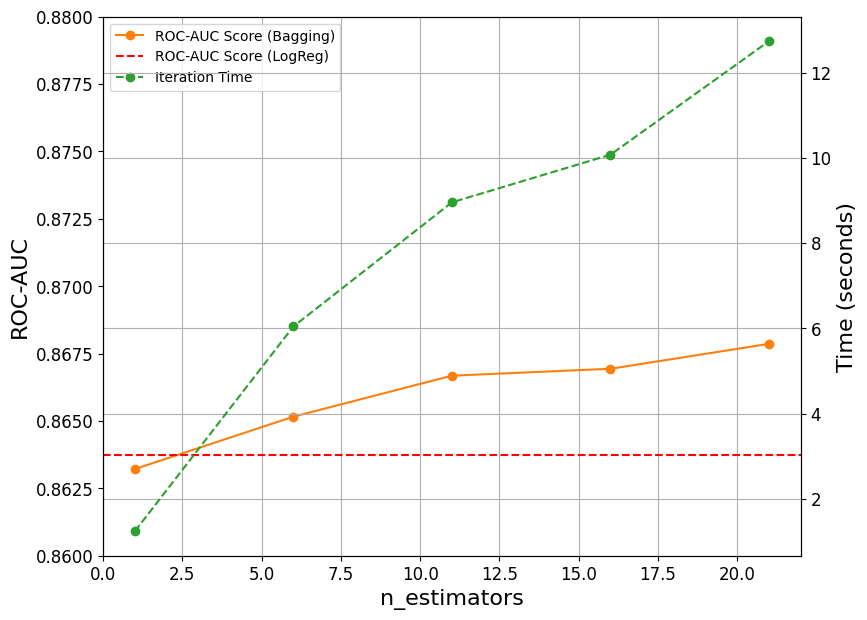

In [47]:
# Строим график
n_estimators_values = list(range(1, 22, 5))

plt.figure(figsize=(9, 7))

ax1 = plt.gca()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax1.plot(n_estimators_values, roc_auc_scores_logreg, label='ROC-AUC Score (Bagging)', marker='o', color='tab:orange')

# Добавляем горизонтальную пунктирную линию
ax1.axhline(y=0.8637476406624232, linestyle='--',color='red', label='ROC-AUC Score (LogReg)')

ax1.set_xlabel('n_estimators', fontsize=16)
ax1.set_ylabel('ROC-AUC', fontsize=16)
ax1.tick_params(axis='y')
plt.grid(axis='x')

ax1.set_ylim(0.86,0.88)

ax2 = ax1.twinx()
plt.yticks(fontsize=12)

ax2.plot(n_estimators_values, train_predict_times_logreg, label='Iteration Time',
         linestyle='dashed', marker='o', color='tab:green')

ax2.set_ylabel('Time (seconds)', fontsize=16)

ax2.tick_params(axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.grid()
plt.show()

**Вопросы.** Почему качество ансамбля немного лучше классической логистической регрессии? Почему качество ансамбля не улучшается с ростом количества базисов?



### Bagging & RF над деревьями решений

Бэггинг и случайный лес работают только в случае гибких базовых моделей, у которых уже есть высокая дисперсия.

Теперь посмотрим, как ансамблевые методы покажут себя при применении над деревьями решений. Сначала обучим одиночное дерево и посмотрим на его качество предсказания на нашей задаче.

Случай с **одиночным** неограниченным деревом решений:

In [48]:
# Переобучение!
base_tree = DecisionTreeClassifier(random_state=42, class_weight='balanced')

base_tree.fit(X_train, y_train)

# Строим прогнозы на тесте
y_proba = base_tree.predict_proba(X_test)[:,1]
print("ROC AUC score:", roc_auc_score(y_test, y_proba))

ROC AUC score: 0.6983899657630381


In [49]:
# Проверим, какая у неограниченного дерева глубина
tree_depth = base_tree.get_depth()
tree_depth

62

Применим pre-pruning-технику и посмотрим, как качество одиночного дерева зависит от его глубины.

In [50]:
train_scores = []
test_scores = []
for d in range(1, tree_depth+1, 4):
    base_tree = DecisionTreeClassifier(max_depth=d, random_state=42, class_weight='balanced')
    base_tree.fit(X_train, y_train)
    y_proba = base_tree.predict_proba(X_test)[:,1]
    # train_scores.append(roc_auc_score(y_train, y_proba))
    test_scores.append(roc_auc_score(y_test, y_proba))

In [54]:
len(test_scores)

16

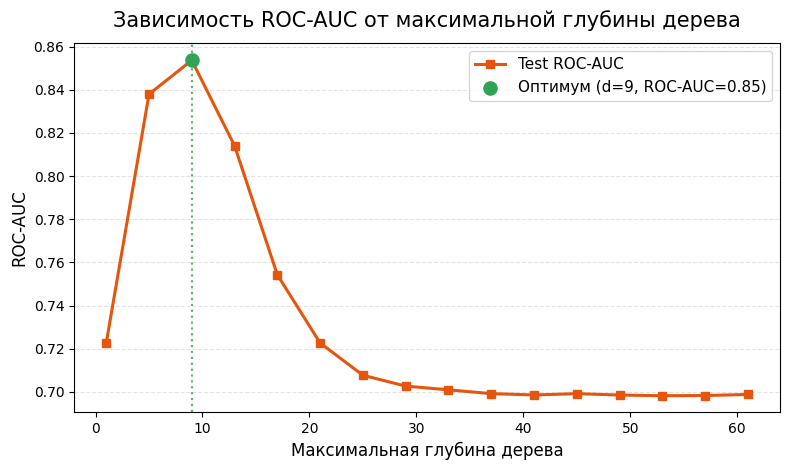

In [56]:
plt.figure(figsize=(8, 4.8))
depths = range(1, tree_depth+1, 4)

# plt.plot(depths, train_scores, label='Train ROC-AUC', marker='o', linewidth=2.2, color="#3182bd")
plt.plot(depths, test_scores, label='Test ROC-AUC', marker='s', linewidth=2.2, color="#e6550d")

# Отметим максимум на тесте
best_idx = np.argmax(test_scores)
plt.scatter(depths[best_idx], test_scores[best_idx], color="#31a354", s=90, zorder=5, label=f'Оптимум (d={depths[best_idx]}, ROC-AUC={test_scores[best_idx]:.2f})')
plt.axvline(depths[best_idx], color="#31a354", linestyle=':', linewidth=1.6, alpha=0.8)

plt.xlabel('Максимальная глубина дерева', fontsize=12)
plt.ylabel('ROC-AUC', fontsize=12)
plt.title('Зависимость ROC-AUC от максимальной глубины дерева', fontsize=15, pad=12)
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.legend(fontsize=11, frameon=True)
plt.tight_layout()
plt.show()

In [57]:
# Максимальный ROC-AUC
test_scores[best_idx]

0.8536879658783718

Почти максимальное качество, которое может выдать одиночное дерево на наших данных, — это примерно ROC-AUC=0,852 при ` max_depth=9`.

Применим методы ансамблирования (бэггинг и случайный лес) над деревьями решений. Посмотрим, как изменяется качество предсказаний на тестовых данных.

Обучим ансамбли на **трёх неограниченных деревьях решений**.

In [58]:
# Берём неограниченное дерево как базис
base_tree = DecisionTreeClassifier(random_state=42, class_weight='balanced')

In [59]:
bagging_classifier = BaggingClassifier(
        estimator=base_tree,
        n_estimators=3,
        max_samples=1.0,
        bootstrap=True,
        oob_score=False,
        n_jobs=-1,
        random_state=42)

rf_classifier = RandomForestClassifier(
        n_estimators=3,
        criterion='gini',
        max_depth=None,
        max_samples=1.0,
        max_features='sqrt',
        bootstrap=True,
        oob_score=False,
        n_jobs=-1,
        random_state=42)

bagging_classifier.fit(X_train, y_train)
rf_classifier.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",3
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [60]:
y_proba = bagging_classifier.predict_proba(X_test)[:,1]
print('Bagging ROC-AUC:', roc_auc_score(y_test, y_proba))

y_proba = rf_classifier.predict_proba(X_test)[:,1]
print('Random Forest ROC-AUC:', roc_auc_score(y_test, y_proba))

Bagging ROC-AUC: 0.7929771289592842
Random Forest ROC-AUC: 0.7874084415018203


Учитывая то, что ансамбли сейчас обучались на неограниченных деревьях, прирост в качестве составил от ROC-AUC = 0,7 (неограниченное дерево) до 0,79 (для обоих ансамблей).

Тем не менее пока что наши ансамбли уступают ограниченному дереву с глубиной 9 (ROC-AUC = 0,79 против 0,85). Это было ожидаемо. Мы взяли всего три дерева в качестве базовых моделей наших ансамблей.

Посмотрим, что будет происходить с качеством бэггинга и леса, если мы попробуем увеличить количество базовых деревьев.

После этого в следующих секциях мы посмотрим, как другие гиперпараметры ансамблей могут ещё сильнее улучшать качество ансамблей.

####  `n_estimators`

In [61]:
# Снова неограниченное дерево
base_tree = DecisionTreeClassifier(random_state=42, class_weight='balanced')

Увеличим количество базисных деревьев. Пока возьмём `n_estimators` от 1 до 41, так как обучение на большем количестве деревьев занимает много времени.

Далее мы разберём, как ускорить обучение, и будем обучаться уже на большем количестве базисов.

In [62]:
# Время загрузки 15 минут
roc_auc_scores = []
train_predict_times = []
roc_auc_scores_rf = []
train_predict_times_rf = []

# Посмотрим на качество ансамблей для случаев от 1 до 41 базовых деревьев
for n_estimators in tqdm(range(1, 42, 4)):

    bagging_classifier = BaggingClassifier(
        estimator=base_tree,
        n_estimators=n_estimators,
        n_jobs=-1,
        random_state=42
    )

    rf_classifier = RandomForestClassifier(
        n_estimators=n_estimators,
        n_jobs=-1,
        random_state=42)

    # Замеряем время обучения для Bagging
    start_time = time()
    bagging_classifier.fit(X_train, y_train)
    y_proba = bagging_classifier.predict_proba(X_test)[:,1]
    end_time = time()

    # Замеряем время обучения для RF
    start_time_rf = time()
    rf_classifier.fit(X_train, y_train)
    y_proba_rf = rf_classifier.predict_proba(X_test)[:,1]
    end_time_rf = time()

    # Сохраняем метрики и время
    roc_auc_scores.append(roc_auc_score(y_test, y_proba))
    train_predict_times.append(end_time - start_time)

    roc_auc_scores_rf.append(roc_auc_score(y_test, y_proba_rf))
    train_predict_times_rf.append(end_time_rf - start_time_rf)

100%|██████████| 11/11 [01:45<00:00,  9.61s/it]


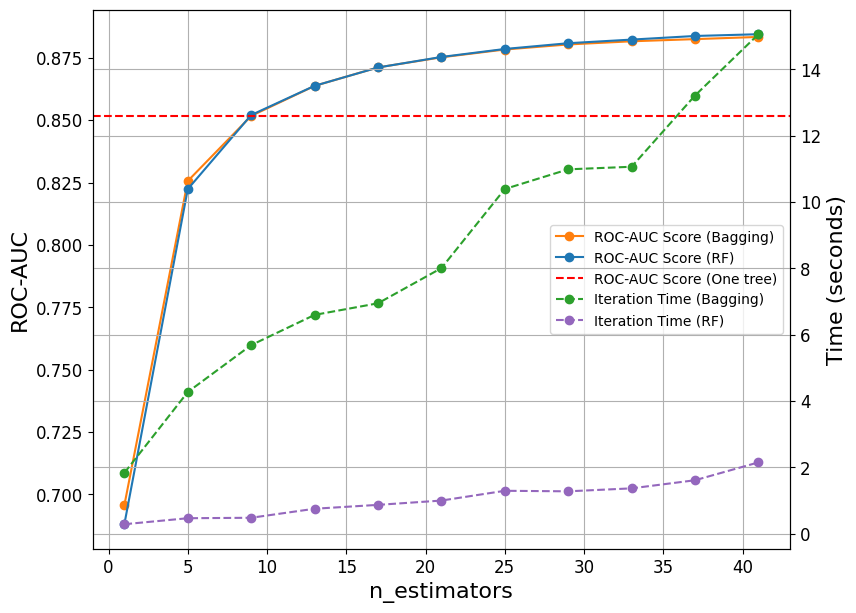

In [63]:
# Строим график
n_estimators_values = list(range(1, 42, 4))

plt.figure(figsize=(9, 7))

ax1 = plt.gca()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax1.plot(n_estimators_values, roc_auc_scores, label='ROC-AUC Score (Bagging)', marker='o', color='tab:orange')
ax1.plot(n_estimators_values, roc_auc_scores_rf, label='ROC-AUC Score (RF)', marker='o', color='tab:blue')

ax1.axhline(y=0.8517968859294183, linestyle='--',color='red', label='ROC-AUC Score (One tree)')

ax1.set_xlabel('n_estimators', fontsize=16)
ax1.set_ylabel('ROC-AUC', fontsize=16)
ax1.tick_params(axis='y')
plt.grid(axis='x')

ax2 = ax1.twinx()
plt.yticks(fontsize=12)

ax2.plot(n_estimators_values, train_predict_times, label='Iteration Time (Bagging)',
         linestyle='dashed', marker='o', color='tab:green')
ax2.plot(n_estimators_values, train_predict_times_rf, label='Iteration Time (RF)',
         linestyle='dashed', marker='o', color='tab:purple')

ax2.set_ylabel('Time (seconds)', fontsize=16)

ax2.tick_params(axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.grid()
plt.show()

**Вопрос.** Какой вывод можно сделать про сравнение перфомансов ансамблей бэггинга и леса и качеством одиночных деревьев?



Выше мы обучали ансамбли на примерно 40 базисных деревьях решений. При увеличении количества базисов тестовый ROC-AUC продолжает расти. Казалось бы, что можно тогда обучить на 1000 базисных деревьях, чтобы улучшить показатели. Но проблема во времени обучения — оно растёт линейно (особенно для бэггинга), а значит, обучение нескольких тысяч деревьев циклом от 1 до 1000 базисов (даже с шагом 4) может занять огромное количество времени.

Оптимизируем процесс обучения с помощью настройки `warm_start`, которая позволяет использовать уже обученные деревья для ансамблей циклом от 1 до $n$ базисов.

#### `n_estimators` & `warm_start`

В scikit-learn гиперпараметр `warm_start` в ансамблевых моделях (например, `BaggingClassifier`, `RandomForestClassifier`, `GradientBoostingClassifier`) решает, сбрасывать ли модель при повторном вызове `.fit()` или продолжать обучение, добавляя новые деревья к уже построенным.

`warm_start=True` — при повторном обучении модель сохраняет уже обученные базовые модели (деревья) и достраивает новые, увеличивая `n_estimators` или продолжая обучение с текущего состояния.

`warm_start=False` (по умолчанию) — каждый вызов `.fit()` создаёт модель с нуля, даже если гиперпараметры не изменились.

Используем `warm_start=True`, чтобы сильно ускорить обучение и посмотреть на качество ансамблей на большом количестве базисов (например, на 180 базисах).

In [64]:
# Время загрузки 15 минут
roc_auc_scores_warm = []
train_predict_times_warm = []
roc_auc_scores_rf_warm = []
train_predict_times_rf_warm = []

bagging_classifier = BaggingClassifier(
        estimator=base_tree,
        n_estimators=12,
        warm_start=True, # Переиспользуем уже обученные деревья
        n_jobs=-1,
        random_state=42
    )

rf_classifier = RandomForestClassifier(
    n_estimators=12,
    warm_start=True,
    n_jobs=-1,
    random_state=42)

# Попробуем теперь обучаться на 180 базисах
for i in tqdm(range(15)):

    start_time = time()
    bagging_classifier.fit(X_train, y_train)
    y_proba = bagging_classifier.predict_proba(X_test)[:, 1]
    end_time = time()

    start_time_rf = time()
    rf_classifier.fit(X_train, y_train)
    y_proba_rf = rf_classifier.predict_proba(X_test)[:, 1]
    end_time_rf = time()

    roc_auc_scores_warm.append(roc_auc_score(y_test, y_proba))
    train_predict_times_warm.append(end_time - start_time)

    roc_auc_scores_rf_warm.append(roc_auc_score(y_test, y_proba_rf))
    train_predict_times_rf_warm.append(end_time_rf - start_time_rf)

    # Добавляем ещё 12 деревьев
    bagging_classifier.n_estimators += 12
    rf_classifier.n_estimators += 12

 33%|███▎      | 5/15 [00:30<01:04,  6.44s/it]/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
100%|██████████| 15/15 [02:32<00:00, 10.14s/it]


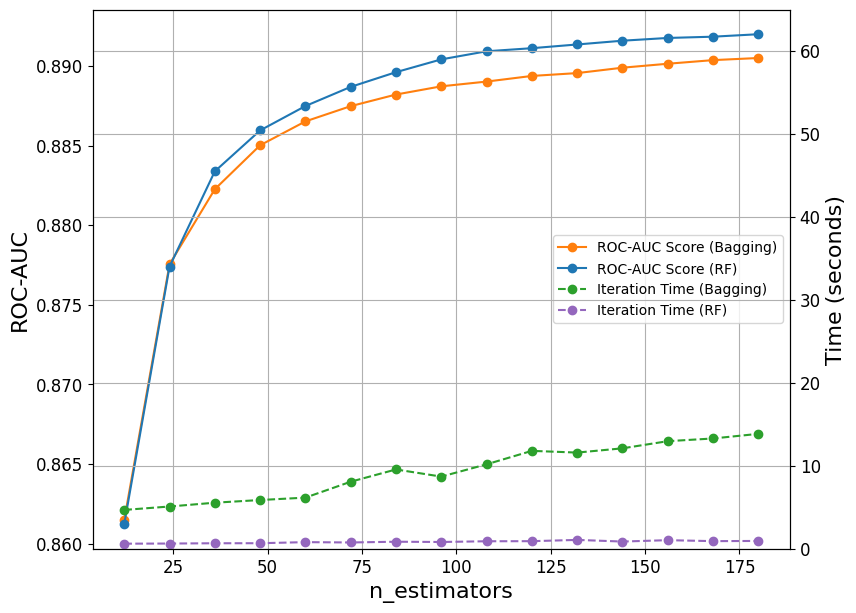

In [65]:
# Строим график
n_estimators_values = list(range(12, 192, 12))

plt.figure(figsize=(9, 7))

ax1 = plt.gca()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax1.plot(n_estimators_values, roc_auc_scores_warm, label='ROC-AUC Score (Bagging)', marker='o', color='tab:orange')
ax1.plot(n_estimators_values, roc_auc_scores_rf_warm, label='ROC-AUC Score (RF)', marker='o', color='tab:blue')
ax1.set_xlabel('n_estimators', fontsize=16)
ax1.set_ylabel('ROC-AUC', fontsize=16)
ax1.tick_params(axis='y')
plt.grid(axis='x')

ax2 = ax1.twinx()
plt.yticks(fontsize=12)

ax2.plot(n_estimators_values, train_predict_times_warm, label='Iteration Time (Bagging)',
         linestyle='dashed', marker='o', color='tab:green')
ax2.plot(n_estimators_values, train_predict_times_rf_warm, label='Iteration Time (RF)',
         linestyle='dashed', marker='o', color='tab:purple')

ax2.set_ylim(0, 65)

ax2.set_ylabel('Time (seconds)', fontsize=16)

ax2.tick_params(axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.grid()
plt.show()

**Вопрос.** Как при использовании `warm_start` увеличение числа деревьев влияет на ROC-AUC и время обучения для бэггинга и случайного леса? Имеет ли смысл увеличивать количество базисов ещё больше?

#### `max_depth`

Неограниченное дерево — алгоритм, который силён своим низким смещением, однако слаб чрезвычайно высокой дисперсией. Поэтому в примерах выше мы и использовали неограниченное дерево как базис для ансамблей, которые в свою очередь помогают снизить дисперсию одиночного дерева.

Теперь посмотрим, обязательно ли для ансамблей строить неограниченные по глубине деревья и можно ли обойтись обрезанными деревьями.

Глубина неограниченного дерева на наших данных = 53. Учитывая то, что и бэггинг, и лес используют рандомизацию в виде бутстрэпа (лес также использует рандомизацию признаков), глубина неограниченных базисных деревьев может отличаться от значения 53.

Возьмём 53 в качестве максимума и обрежем деревья так, чтобы их глубина была меньше 53.

##### Задание 1 [1 балл]

- Построй ансамбли бэггинга и случайного леса над деревьями решений глубиной от 1 до 51 (включительно) с шагом 5. Количество базисных деревьев для обоих ансамблей установи на уровне 30.

- Для каждого шага в цикле измерь тестовый ROC-AUC получившихся ансамблей.

- Замерь время обучения и предсказания отдельно для бэггинга и случайного леса для каждого шага в цикле.

- Все метрики качества сохрани в массивах `roc_auc_scores_depth` и `roc_auc_scores_rf_depth` (для бэггинга и леса соответственно). Время обучения/предсказания сохрани в массивах `train_predict_times_depth` и `train_predict_times_rf_depth`.

- Построй график зависимости ROC-AUC и времени обучения/предсказания обоих ансамблей от глубины базисных деревьев.

In [72]:
import time
from sklearn.metrics import roc_auc_score

roc_auc_scores_depth = []
train_predict_times_depth = []
roc_auc_scores_rf_depth = []
train_predict_times_rf_depth = []

max_depths = list(range(1, 52, 5))

for d in max_depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42, class_weight='balanced')
    bag = BaggingClassifier(
        estimator=tree,
        n_estimators=30,
        random_state=42,
        n_jobs=-1,
    )
    t0 = time.perf_counter()
    bag.fit(X_train, y_train)
    t1 = time.perf_counter()
    proba = bag.predict_proba(X_test)[:, 1]
    t2 = time.perf_counter()
    roc_auc_scores_depth.append(roc_auc_score(y_test, proba))
    train_predict_times_depth.append((t1 - t0) + (t2 - t1))

    rf = RandomForestClassifier(
        n_estimators=30,
        max_depth=d,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced',
    )
    t0 = time.perf_counter()
    rf.fit(X_train, y_train)
    t1 = time.perf_counter()
    proba = rf.predict_proba(X_test)[:, 1]
    t2 = time.perf_counter()
    roc_auc_scores_rf_depth.append(roc_auc_score(y_test, proba))
    train_predict_times_rf_depth.append((t1 - t0) + (t2 - t1))


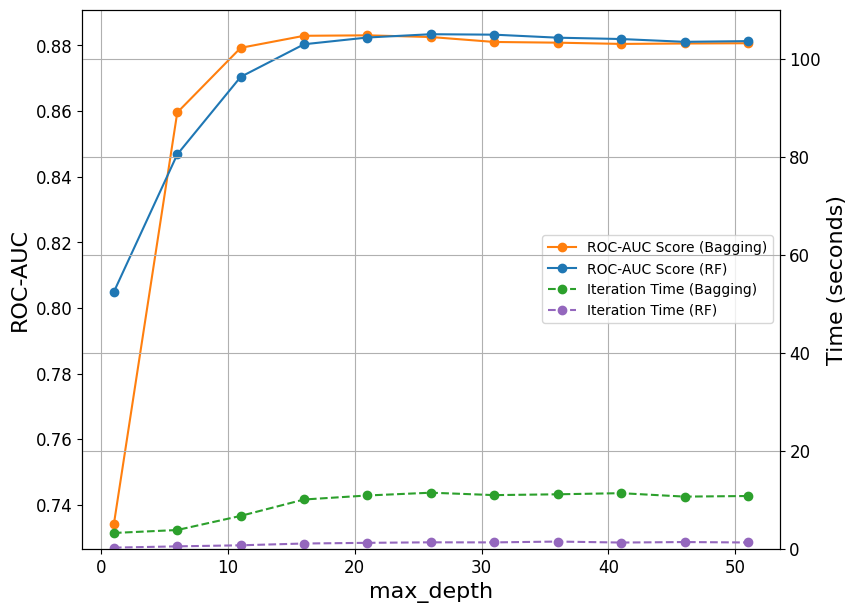

In [73]:
# Строим график
n_estimators_values = list(range(1, 54, 5))

plt.figure(figsize=(9, 7))

ax1 = plt.gca()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax1.plot(n_estimators_values, roc_auc_scores_depth, label='ROC-AUC Score (Bagging)', marker='o', color='tab:orange')
ax1.plot(n_estimators_values, roc_auc_scores_rf_depth, label='ROC-AUC Score (RF)', marker='o', color='tab:blue')
ax1.set_xlabel('max_depth', fontsize=16)
ax1.set_ylabel('ROC-AUC', fontsize=16)
ax1.tick_params(axis='y')
plt.grid(axis='x')

ax2 = ax1.twinx()
plt.yticks(fontsize=12)

ax2.plot(n_estimators_values, train_predict_times_depth, label='Iteration Time (Bagging)',
         linestyle='dashed', marker='o', color='tab:green')
ax2.plot(n_estimators_values, train_predict_times_rf_depth, label='Iteration Time (RF)',
         linestyle='dashed', marker='o', color='tab:purple')

ax2.set_ylim(0, 110)

ax2.set_ylabel('Time (seconds)', fontsize=16)

ax2.tick_params(axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.grid()
plt.show()

##### Выводы

При построении ансамблей необязательно строить неограниченные деревья глубиной 50. Можно использовать деревья глубиной 15–20, которые дают **немного улучшенные** метрики качества.

- Если хочется использовать бэггинг или лес без настройки, то можно не подбирать оптимальный `max_depth` и обучаться на неограниченных деревьях.

- Однако в случаях, когда важны скорость, память и другие вычислительные ресурсы, лучше обучаться на укороченных деревьях.

- Если датасет имеет много выбросов и шумных наблюдений, неограниченные деревья могут переобучиться до такой степени, что даже ансамбль этих деревьев не сможет значительно снизить их дисперсию. В таком случае также рекомендуется брать за базисы ограниченные деревья.

#### `max_features`

Переходим к самому важному гиперпараметру — количеству признаков для обучения деревьев на каждом сплите (случайный лес) или на каждом базисном дереве (бэггинг).

При обучении деревьев можно уменьшить количество признаков, на которых эти деревья обучаются. Это приводит к двум эффектам:
- снижается корреляция между деревьями и, как следствие, уменьшается дисперсия всего ансамбля;
- увеличивается смещение каждого дерева, так как деревья обучаются не на всех доступных данных.

Посмотрим, какой эффект победит и чем они отличаются в случаях бэггинга и случайного леса.

In [74]:
# График уже нарисован, запускать не нужно. Грузится больше часа!!!
roc_auc_scores_feats = []
train_predict_times_feats = []
roc_auc_scores_rf_feats = []
train_predict_times_rf_feats = []

base_tree = DecisionTreeClassifier(random_state=42, class_weight='balanced')

for i in tqdm(range(1, len(df.columns), 10)):

    bagging_classifier = BaggingClassifier(
        estimator=base_tree,
        n_estimators=100,
        max_features=i,
        n_jobs=-1,
        random_state=42
    )

    rf_classifier = RandomForestClassifier(
        n_estimators=100,
        max_features=i,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42)

    # Замеряем время обучения для Bagging
    start_time = time.time()
    bagging_classifier.fit(X_train, y_train)
    y_proba = bagging_classifier.predict_proba(X_test)[:,1]
    end_time = time.time()

    # Замеряем время обучения для RF
    start_time_rf = time.time()
    rf_classifier.fit(X_train, y_train)
    y_proba_rf = rf_classifier.predict_proba(X_test)[:,1]
    end_time_rf = time.time()

    # Сохраняем метрики и время
    roc_auc_scores_feats.append(roc_auc_score(y_test, y_proba))
    train_predict_times_feats.append(end_time - start_time)

    roc_auc_scores_rf_feats.append(roc_auc_score(y_test, y_proba_rf))
    train_predict_times_rf_feats.append(end_time_rf - start_time_rf)

 75%|███████▌  | 9/12 [03:52<01:54, 38.04s/it]/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
 92%|█████████▏| 11/12 [05:47<00:48, 48.26s/it]/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
100%|██████████| 12/12 [06:54<00:00, 34.57s/it]


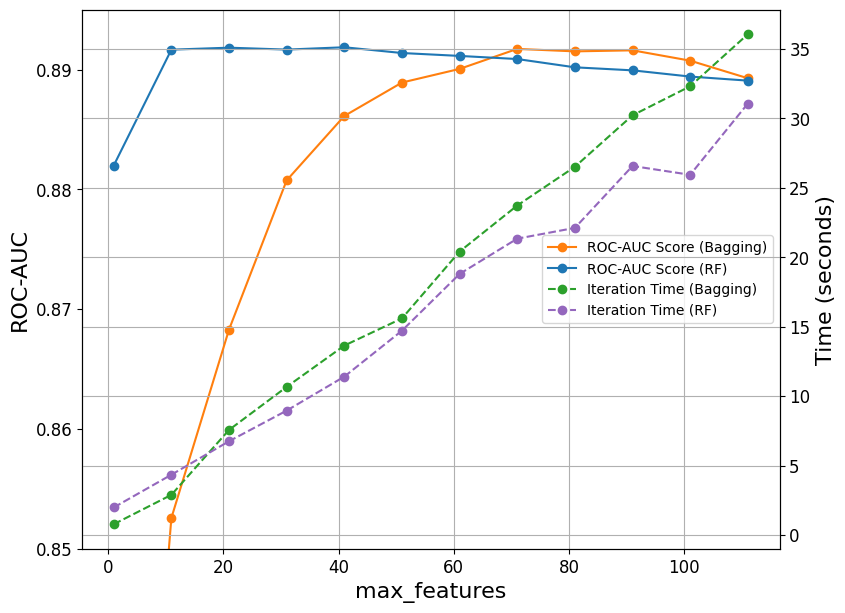

In [75]:
# Строим график
n_estimators_values = list(range(1, len(df.columns), 10))

plt.figure(figsize=(9, 7))

ax1 = plt.gca()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax1.plot(n_estimators_values, roc_auc_scores_feats, label='ROC-AUC Score (Bagging)', marker='o', color='tab:orange')
ax1.plot(n_estimators_values, roc_auc_scores_rf_feats, label='ROC-AUC Score (RF)', marker='o', color='tab:blue')
ax1.set_xlabel('max_features', fontsize=16)
ax1.set_ylabel('ROC-AUC', fontsize=16)
ax1.tick_params(axis='y')
plt.grid(axis='x')
ax1.set_ylim(0.85, 0.895)

ax2 = ax1.twinx()
plt.yticks(fontsize=12)

ax2.plot(n_estimators_values, train_predict_times_feats, label='Iteration Time (Bagging)',
         linestyle='dashed', marker='o', color='tab:green')
ax2.plot(n_estimators_values, train_predict_times_rf_feats, label='Iteration Time (RF)',
         linestyle='dashed', marker='o', color='tab:purple')

#ax2.set_ylim(0, 205)

ax2.set_ylabel('Time (seconds)', fontsize=16)

ax2.tick_params(axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.grid()
plt.show()

**Вопрос.** Какие выводы можешь сделать по этому графику?



### Isolation Forest


>**Isolation Forest** — это метод для поиска аномалий — объектов, которые сильно выбиваются из общей картины.

Модель изолирует такие точки с помощью случайных разбиений. Она многократно строит «деревья изоляции»: в каждом узле случайно выбирается признак и порог, по которому делится выборка. Если объект резко отличается от остальных, он отделяется быстро — путь от корня до листа получается коротким. Чем короче средний путь по ансамблю, тем больше вероятность, что это — аномалия.


Чтобы оценить степень аномальности, короткий путь переводим в нормированный **скор**. Для этого делим среднюю длину пути на ожидаемую в случайном дереве такого же размера — так результаты сопоставимы при разных подвыборках.

Скор лежит в диапазоне (0, 1]: ближе к 1 — явная аномалия, ближе к 0 — нормальный объект.

Параметры:
- `max_samples` — размер подвыборки на дерево, отвечает за скорость и устойчивость;
- `n_estimators` — количество деревьев, влияет на стабильность;
- `contamination` — доля объектов, которую помечаем как аномалии.

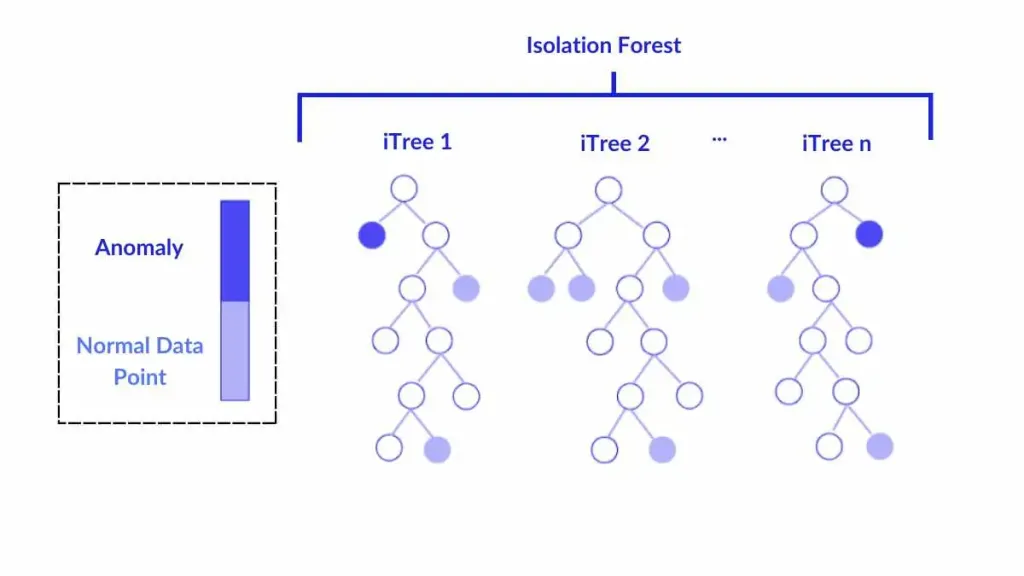

Источник: https://spotintelligence.com/2024/05/21/isolation-forest/.

[Подробнее про изолированный лес.](https://habr.com/ru/companies/otus/articles/881086/)

Применим Isolation Forest, чтобы вычистить выбросы перед обучением ансамблей. Когда удалим небольшую часть подозрительных наблюдений, проверим, как это влияет на качество леса решений.

`contamination` — это важнейший гиперпараметр в изолированном лесе. Он определяет предполагаемую долю выбросов в датасете. В практике работы с Isolation Forest параметр `contamination` обычно выбирают исходя из ожидаемой доли аномалий в данных.

Если эта доля известна из бизнес-логики или разметки, её и используют — например, 1–5% для выявления бракованных изделий или менее 1% для задач финансового фрода. Когда точной оценки нет, часто начинают с 1% и подбирают значение экспериментально, проверяя качество на валидации.

Построим изолированный лес на всех признаках (без целевой переменной). В нашем случае зададим `contamination=0.01`, предполагая около 1% выбросов.

In [76]:
from sklearn.ensemble import IsolationForest

In [77]:
numeric

Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm',
       'Temp9am', 'Temp3pm'],
      dtype='str')

In [78]:
scaler = StandardScaler()
df[numeric] = scaler.fit_transform(df[numeric])

In [79]:
df.head(3)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,RainToday,RainTomorrow,Season_Spring,Season_Summer,Season_Winter
0,0.203641,-0.053022,-0.202134,0.0,0.0,0.307418,0.682165,0.638242,0.099948,-1.423740,...,0,0,0,1,0,0,0,0,1,0
1,-0.730616,0.256177,-0.272266,0.0,0.0,0.307418,-1.146215,0.404603,-1.297664,-1.279608,...,0,0,0,0,1,0,0,0,1,0
2,0.125787,0.340505,-0.272266,0.0,0.0,0.460618,0.567891,0.871882,-1.608245,-1.039388,...,0,0,0,0,1,0,0,0,1,0


##### Задание 2 [1 балл]

- Построй модель обнаружения аномалий с помощью алгоритма Isolation Forest на данных df, используя класс из библиотеки `sklearn.ensemble`.

- Раздели данные на $X$ (все признаки, кроме `RainTomorrow`) и $y$ (столбец `RainTomorrow`). Деления на train- и test-выборки не будет, так как мы хотим обучиться и предсказывать на одних и тех же данных.

- Обучи Isolation Forest на 300 базисных деревьях, определи пропорцию выбросов, равную 1%.

- Посчитай anomaly score для каждого наблюдения, используя метод `decision_function()`. Сохрани результаты в массив `anomaly_score`.

- Для каждого наблюдения определи, нормальный ли это объект или выброс. Используй метод `predict()`. Создай массив `labels_outlier`, который будет хранить `True` для выбросов и `False` для «нормисов».

Используй для решения [sklearn IRF.](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html#)

In [80]:
from sklearn.ensemble import IsolationForest

X = df.drop(columns=['RainTomorrow'])
y = df['RainTomorrow']

iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=42, n_jobs=-1)
iso.fit(X)
# В sklearn decision_function больше у «нормальных»; инвертируем, чтобы совпасть с текстом семинара
anomaly_score = -iso.decision_function(X)
labels_outlier = iso.predict(X) == -1


Метод `decision_function` возвращает «негативность» точки: чем выше `anomaly_score`, тем сильнее она похожа на аномалию. Массив `labels_outlier` помечает наблюдения как выбросы (True) или нормальные (False).


Теперь визуализируем распределение `anomaly_score`. Так мы убедимся, что действительно есть небольшой «хвост» высоких значений. Затем сделаем PCA до 2 компонент и отметим выбросы крестиками — это даёт интуитивную картинку, где в пространстве признаков лежат подозрительные точки. Такой просмотр часто выявляет кластеры аномалий и подтверждает, что выбрали правильный уровень `contamination`.

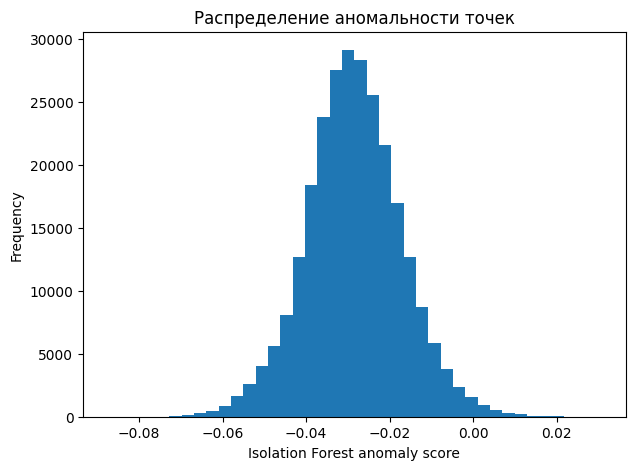

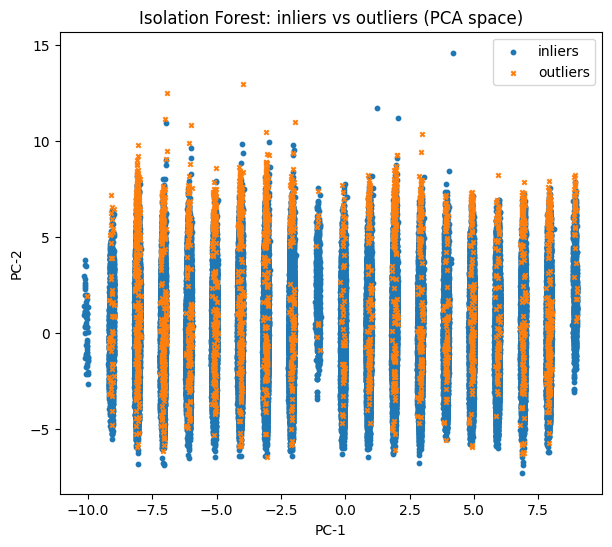

In [81]:
from sklearn.decomposition import PCA

# Гистограмма скорингов
plt.figure(figsize=(7,5))
plt.hist(anomaly_score, bins=40)
plt.xlabel("Isolation Forest anomaly score")
plt.ylabel("Frequency")
plt.title("Распределение аномальности точек")
plt.show()

# PCA-проекция (две главные компоненты) с выбросами
pca = PCA(n_components=2)
coords = pca.fit_transform(X)

plt.figure(figsize=(7,6))
plt.scatter(
    coords[~labels_outlier, 0],
    coords[~labels_outlier, 1],
    s=10,
    label="inliers",
)
plt.scatter(
    coords[labels_outlier, 0],
    coords[labels_outlier, 1],
    s=10,
    marker="x",
    label="outliers",
)
plt.legend()
plt.title("Isolation Forest: inliers vs outliers (PCA space)")
plt.xlabel("PC-1")
plt.ylabel("PC-2")
plt.show()

Посчитаем, сколько наблюдений помечено как выбросы и как «нормальные». Это быстрый sanity-check перед фильтрацией данных.

In [82]:
pd.Series(labels_outlier).value_counts()

False    262094
True       2648
Name: count, dtype: int64

Удалим найденные выбросы из матрицы признаков и целевой переменной. В результате мы получим «очищенную» выборку, с которой далее будем сравнивать качество моделей относительно исходной.

In [83]:
X_clean = X[~labels_outlier]
y_clean = y.values[~labels_outlier]

In [84]:
# Выводим, сколько аномалий удалили
len(X), len(X_clean)

(264742, 262094)

Делаем сплит на обучающую и тестовую части уже для «чистой» выборки, со стратификацией по таргету. Аналогичный сплит для «грязной» выборки (переменные `X_train`, `X_test`, `y_train`, `y_test`) мы делали в начале семинара.

In [85]:
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean, y_clean, test_size=0.3, random_state=42, stratify=y_clean)

Построим два случайных леса с `warm_start=True`, постепенно наращивая число деревьев (по 12 за итерацию), и на каждом шаге считаем ROC-AUC.

Один лес учится на исходных данных, второй — на очищенных от выбросов. Это позволяет сравнить влияние чистки при одинаковой архитектуре.

Траектории ROC-AUC (массивы `roc_auc_scores_rf_*`) показывают, как растёт качество по мере увеличения ансамбля.

In [86]:
roc_auc_scores_rf_orig = []
roc_auc_scores_rf_clean = []

rf_classifier_orig = RandomForestClassifier(
        n_estimators=12,
        warm_start=True, # Переиспользуем уже обученные деревья
        n_jobs=-1,
        random_state=42)

rf_classifier_clean = RandomForestClassifier(
    n_estimators=12,
    warm_start=True,
    n_jobs=-1,
    random_state=42)

for i in tqdm(range(15)):

    rf_classifier_orig.fit(X_train, y_train)
    y_proba_rf_orig = rf_classifier_orig.predict_proba(X_test)[:, 1]

    rf_classifier_clean.fit(X_train_clean, y_train_clean)
    y_proba_rf_clean = rf_classifier_clean.predict_proba(X_test_clean)[:, 1]

    roc_auc_scores_rf_orig.append(roc_auc_score(y_test, y_proba_rf_orig))
    roc_auc_scores_rf_clean.append(roc_auc_score(y_test_clean, y_proba_rf_clean))

    # Добавляем ещё 12 деревьев
    rf_classifier_orig.n_estimators += 12
    rf_classifier_clean.n_estimators += 12

100%|██████████| 15/15 [00:23<00:00,  1.58s/it]


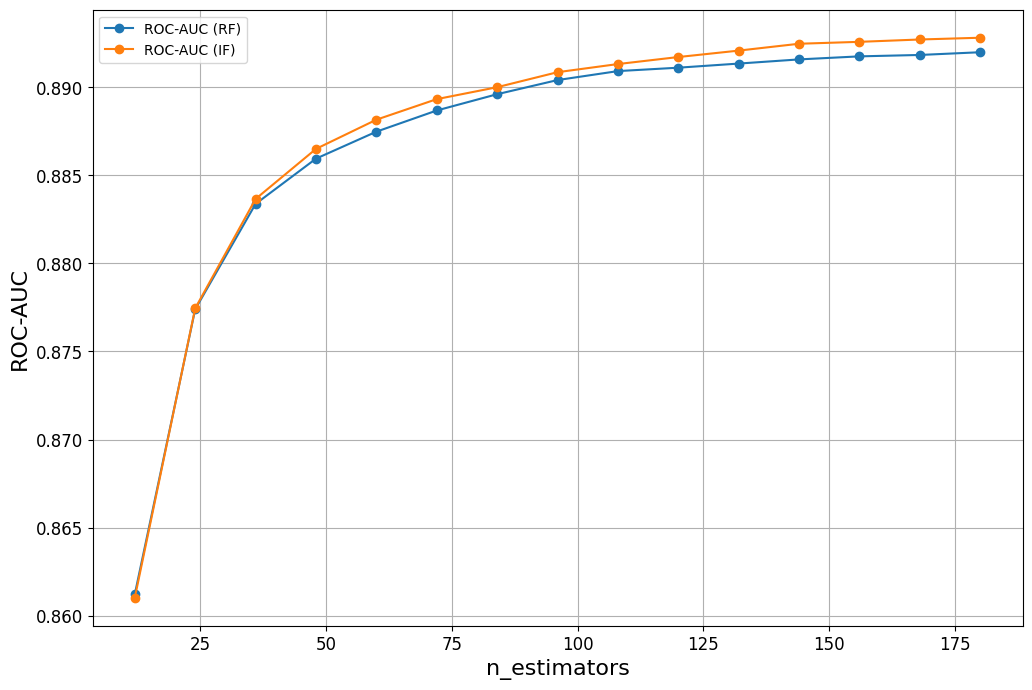

In [87]:
# Строим график
n_estimator_values = range(12, 192, 12)

plt.figure(figsize=(12, 8))

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.plot(n_estimator_values, roc_auc_scores_rf_orig, label='ROC-AUC (RF)', marker='o', color='tab:blue')
plt.plot(n_estimator_values, roc_auc_scores_rf_clean, label='ROC-AUC (IF)', marker='o', color='tab:orange')
plt.xlabel('n_estimators', fontsize=16)
plt.ylabel('ROC-AUC', fontsize=16)
plt.legend()
plt.tick_params(axis='y')

plt.grid(True)
plt.show()

**Вопрос.** Какой вывод можно сделать по графику? Что может произойти, если увеличить гиперпараметр `contamination`? Если уменьшить?



### Random Forest: `oob_score`

OOB-оценка (Out-of-Bag) — незатратная замена валидации для бэггинга или леса: часть объектов не попадает в бутстрэп конкретного дерева и может служить «мини-валидом».
>**Примечание.** В scikit-learn OOB доступен только для алгоритмов, которые используют бутстрэповую выборку при обучении базовых моделей — только для бэггинга и случайного леса.

Сейчас ты сверишь OOB c тестовой метрикой, чтобы понять, можно ли опираться на OOB-оценку. Для обучения используем алгоритм случайного леса.

Обучаем случайный лес с `oob_score=True`, чтобы у него сохранилась информация о предсказаниях для внемешковых наблюдений.

In [88]:
rf_classifier = RandomForestClassifier(
        n_estimators=100,
        n_jobs=-1,
        oob_score=True,
        random_state=42)

rf_classifier.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

##### Задание 3 [1 балл]

- Используя обученную модель `rf_classifier`, измерь две метрики ROC-AUC: test-ROC-AUC и OOB-ROC-AUC.

- Для этого задания тебе понадобятся методы `roc_auc_score`, `predict_proba`, а также один из двух методов `oob_score_` и `oob_decision_function_`.

>**Внимание.** Только один из двух последних методов даёт верный результат. Задание всего на несколько строк кода, но с подвохом, поэтому не теряй бдительность.

In [89]:
test_proba = rf_classifier.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_proba)

oob_margins = rf_classifier.oob_decision_function_
mask = ~np.isnan(oob_margins[:, 1])
oob_auc = roc_auc_score(y_train.values[mask], oob_margins[mask, 1])

print('Тестовая метрика:', test_auc)
print('OOB метрика:', oob_auc)


Тестовая метрика: 0.8906587803752165
OOB метрика: 0.8824031668275696


 Для корректного сравнения берём OOB-вероятности (`oob_decision_function_`) и считаем ROC-AUC так же, как на тесте. Получается: тест ROC-AUC = 0,8901, OOB-ROC-AUC = 0,8817. Значит, OOB-оценка чуть занижает истинное значение, но основную тенденцию ловит — значит, OOB годится как «грубая» оценка тестовой метрики.

### Random Forest: важность признаков

Деревья решений лучше ансамблей своей интерпретируемостью: схему работы алгоритма дерева намного легче объяснить клиенту. Более того, результат обучения дерева гораздо более понятен и прозрачен, сравнивая с результатом обучения ансамбля.

Чтобы повысить интерпретируемость ансамбля, можно оценить важность признаков — это помогает определить, какие переменные больше всего влияют на предсказания модели.

Существуют разные алгоритмы измерения важности признаков в ансамблях. Сейчас мы рассмотрим три самых распространённых: MDI, MDA, SHAP.

>**MDI** (анл. Mean Decrease in Impurity) — это способ оценки важности признаков, встроенный в деревья решений и ансамбли (Random Forest, Extra Trees).

 При обучении дерева на каждом сплите уменьшается значение функции неопределённости (например, критерия Джини или энтропии). Важность признака считается как сумма всех таких уменьшений, где признак использовался, усреднённая по деревьям:

$$\Delta H(R, j, t) = H(R) - \left (\frac{|R_\ell|}{|R|} H(R_\ell) + \frac{|R_r|}{|R|} H(R_r)\right),$$

$$\mathrm{MDI}_j^{\mathrm{tree}}
= \sum_{t:\,\text{split on } j}
\frac{\lvert R_t\rvert}{\lvert R\rvert}\;\Delta H(R_t, j, t),$$

$$\mathrm{MDI}_j^{\mathrm{forest}}
= \frac{1}{T}\sum_{t=1}^{T}\mathrm{MDI}_j^{\mathrm{tree}\,t}.$$

MDI быстрый, но имеет ограничения: он склонен завышать важность признаков с большим количеством уникальных значений и может давать смещённые оценки при коррелированных фичах.

>**MDA** (англ. Mean Decrease in Accuracy), или permutation importance, оценивает важность признака по изменению качества модели при случайной перестановке значений этого признака в тестовых данных.

Если перестановка заметно ухудшает метрику (например, ROC-AUC или accuracy), признак считается важным:

$$\mathrm{MDA}_j^{\mathrm{tree}}
= \mathrm{Err}_{\mathrm{perm},j}^{\mathrm{tree}} \;-\; \mathrm{Err}_{\mathrm{base}}^{\mathrm{tree}},$$

$$\mathrm{MDA}_j^{\mathrm{tree\_rel}}
= \frac{\mathrm{Err}_{\mathrm{perm},j}^{\mathrm{tree}} \;-\; \mathrm{Err}_{\mathrm{base}}^{\mathrm{tree}}}{\mathrm{Err}_{\mathrm{base}}^{\mathrm{tree}}},$$

$$\mathrm{MDA}_j^{\mathrm{forest}}
= \frac{1}{R}\sum_{r=1}^{R}
  \bigl(\mathrm{Err}_{\mathrm{perm},j}^{(r)} - \mathrm{Err}_{\mathrm{base}}^{(r)}\bigr).$$

MDA менее подвержен смещению при коррелированных признаках, но требует больше вычислений, так как модель нужно многократно переоценивать на переставленных данных.

>**SHAP** (англ. SHapley Additive exPlanations) — метод, основанный на теории игр, который измеряет вклад каждого признака в предсказание модели через значения Шепли.

Значение Шепли показывает, насколько в среднем признак влияет на результат модели с учётом всех возможных сочетаний признаков. SHAP даёт как локальные, так и глобальные интерпретации, учитывает взаимодействия между признаками, но может быть вычислительно затратным.

На практике MDI используют для быстрой оценки и отбраковки явно неинформативных признаков, MDA — для более честной оценки вклада в качество, а SHAP — для детального анализа и интерпретации модели, особенно если важна прозрачность решений.

#### sklearn `feature_importance` (MDI)

MDI (Mean Decrease in Impurity) показывает, насколько признаки в среднем уменьшают критерий (Gini или entropy) внутри деревьев.

In [90]:
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    n_jobs=-1,
    random_state=42,
)
rf_classifier.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [91]:
rf_classifier.feature_importances_

array([0.04210821, 0.04118129, 0.05159329, 0.02395362, 0.04092011,
       0.0492938 , 0.02754814, 0.02965171, 0.05328207, 0.15002313,
       0.04621042, 0.05305522, 0.02333875, 0.03695969, 0.03971123,
       0.04421381, 0.02661114, 0.00142718, 0.0012817 , 0.00054287,
       0.00133762, 0.00124141, 0.00100941, 0.00130595, 0.00106583,
       0.00127129, 0.00086826, 0.00161465, 0.00126399, 0.0006519 ,
       0.00104201, 0.00151756, 0.00027912, 0.00100777, 0.00113754,
       0.00127205, 0.00081368, 0.00079198, 0.00140736, 0.0008651 ,
       0.0005428 , 0.00106053, 0.00142338, 0.0015914 , 0.00121025,
       0.00103325, 0.00088981, 0.00171315, 0.00138538, 0.00158071,
       0.00114336, 0.00108202, 0.00101935, 0.00164988, 0.0014092 ,
       0.0006777 , 0.00143551, 0.00048976, 0.00112091, 0.00189185,
       0.00138807, 0.00129933, 0.00214043, 0.00146846, 0.00078051,
       0.00232611, 0.00209884, 0.00310381, 0.00266658, 0.0026301 ,
       0.00282979, 0.00302111, 0.00293943, 0.00249478, 0.00254

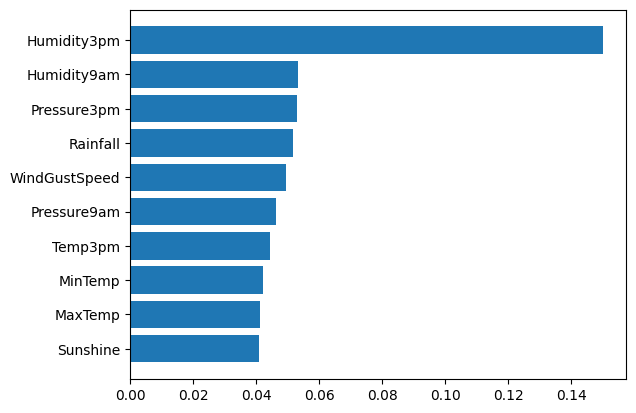

In [92]:
fi = pd.DataFrame({'column': X_train.columns, 'feature_importance': rf_classifier.feature_importances_})
fi = fi.sort_values('feature_importance',ascending=True).tail(10)
plt.barh(fi['column'], fi['feature_importance']);

На графике видно, что по MDI самый важный признак для предсказания — это `Humidity3pm`, причём его вклад заметно выше остальных.

Далее идут `Pressure3pm`, `Humidity9am`, `WindGustSpeed`, `Rainfall` и другие погодные показатели. MDI отражает, насколько сильно каждый признак в среднем снижает неопределённость (англ. impurity) в узлах деревьев.

Однако метод склонен завышать важность признаков с большим числом уникальных значений или тех, которые чаще встречаются в верхней части дерева. Это может объяснять, почему в топе много непрерывных признаков с большим диапазоном значений.

#### Перестановки (MDA)

Проверяем «полезность» фич напрямую по метрике качества: насколько падает ROC-AUC, если перемешать столбец. Это техника Mean Decrease in Accuracy (MDA). Этот подход даёт менее смещённые оценки, чем MDI, но он дороже по времени.

In [93]:
from sklearn.inspection import permutation_importance

In [94]:
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    n_jobs=-1,
    random_state=42,
)
rf_classifier.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

Чтобы ускорить расчёт, при расчёте MDA часто берётся семпл теста (здесь мы возьмём 500 наблюдений). Это компромисс между скоростью и стабильностью оценок.

In [95]:
X_sample = X_test.sample(500, random_state=42)
y_sample = y_test.loc[X_sample.index]

Считаем MDA: 10 перестановок на признак, метрика — ROC-AUC. На больших матрицах это тяжёлая ячейка. Итог — вектор `perm.importances_mean` (среднее падение метрики), возможны отрицательные значения для шумовых фич.

In [96]:
perm = permutation_importance(
    rf_classifier, X_sample, y_sample,
    n_repeats=10,
    #n_jobs=-1,
    random_state=42,
    scoring="roc_auc")

Просмотрим средние изменения метрики по каждому признаку. Большие положительные — важные, близкие к нулю — нейтральные или дубли, отрицательные — вероятно, шум.

In [97]:
perm.importances_mean

array([ 1.21093234e-02, -6.34065150e-04,  6.90866820e-04, -2.35792978e-03,
        3.96422816e-03,  3.45539087e-02, -1.26548836e-03, -1.95767615e-03,
        2.42529920e-03,  5.50791260e-02,  4.78058704e-03,  2.57694645e-02,
       -8.09754036e-04,  1.56032866e-02,  7.08964096e-03,  1.06496526e-02,
       -2.73572693e-03, -4.91400491e-04,  1.59440966e-03, -6.81620036e-04,
       -6.14250614e-04,  4.06858471e-04,  4.83474677e-04,  1.50590473e-04,
        1.54553380e-04, -3.17032575e-05,  6.05003831e-04,  2.85329318e-04,
        1.12282370e-04, -3.23637420e-04,  6.86903913e-05, -1.79651793e-04,
        6.34065150e-05,  1.20208185e-04, -3.67229399e-04,  2.12676019e-04,
        9.51097725e-05, -1.32096906e-04, -2.19280864e-04,  7.67483026e-04,
       -6.65768408e-04, -1.38701752e-04, -1.58516288e-04,  9.11468653e-05,
        4.98005337e-04, -2.85329318e-04, -1.00393649e-04, -4.04216533e-04,
        3.63266492e-04, -4.12142348e-04,  1.14924308e-04, -3.44772925e-04,
        1.99334232e-03, -

Построим также bar-схему по MDA, которую отсортируем по влиянию признака.

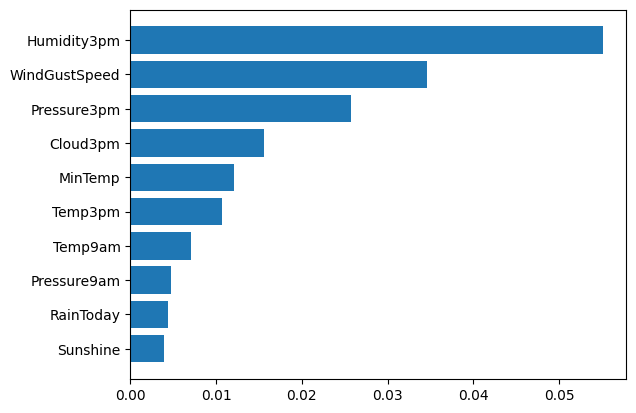

In [98]:
fi = pd.DataFrame({'column': X_train.columns, 'feature_importance': abs(perm.importances_mean)})
fi = fi.sort_values('feature_importance').tail(10)
plt.barh(fi['column'], fi['feature_importance']);

В случае MDA `Humidity3pm` также остаётся главным признаком, но его относительная важность ниже. На втором месте — `Pressure3pm`, затем — `WindGustSpeed`, `Pressure9am` и `MinTemp`.

MDA измеряет падение качества модели при случайной перестановке значений признака, что делает его менее чувствительным к числу уникальных значений и более устойчивым при коррелированных фичах.

Различия между графиками MDI и MDA объясняются природой методов: MDI измеряет влияние признака на структуру деревьев во время обучения, тогда как MDA оценивает реальный вклад признака в итоговую метрику качества. В результате MDI может переоценивать признаки, которые часто выбираются на ранних этапах построения деревьев, а MDA даёт более практичную картину важности для предсказаний. На практике полезно смотреть оба подхода: MDI — для быстрой первичной оценки, MDA — для валидации реальной значимости.

#### SHAP

Метод Shapley values пришёл к нам из теории игр. Он отвечает на вопрос: как распределить выигрыш между игроками?

**Пример.** Есть компания из трёх человек. Прибыль за месяц у них 10 000 долларов. Какую зарплату надо назначить каждому? В начале в компании работал только CEO. Когда он работал один, прибыль была 3 000 долларов. Затем к нему присоединился технический специалист, и прибыль выросла до 5 000. Затем присоединился человек, ответственный за продажи, и прибыль выросла до 10 000 долларов.

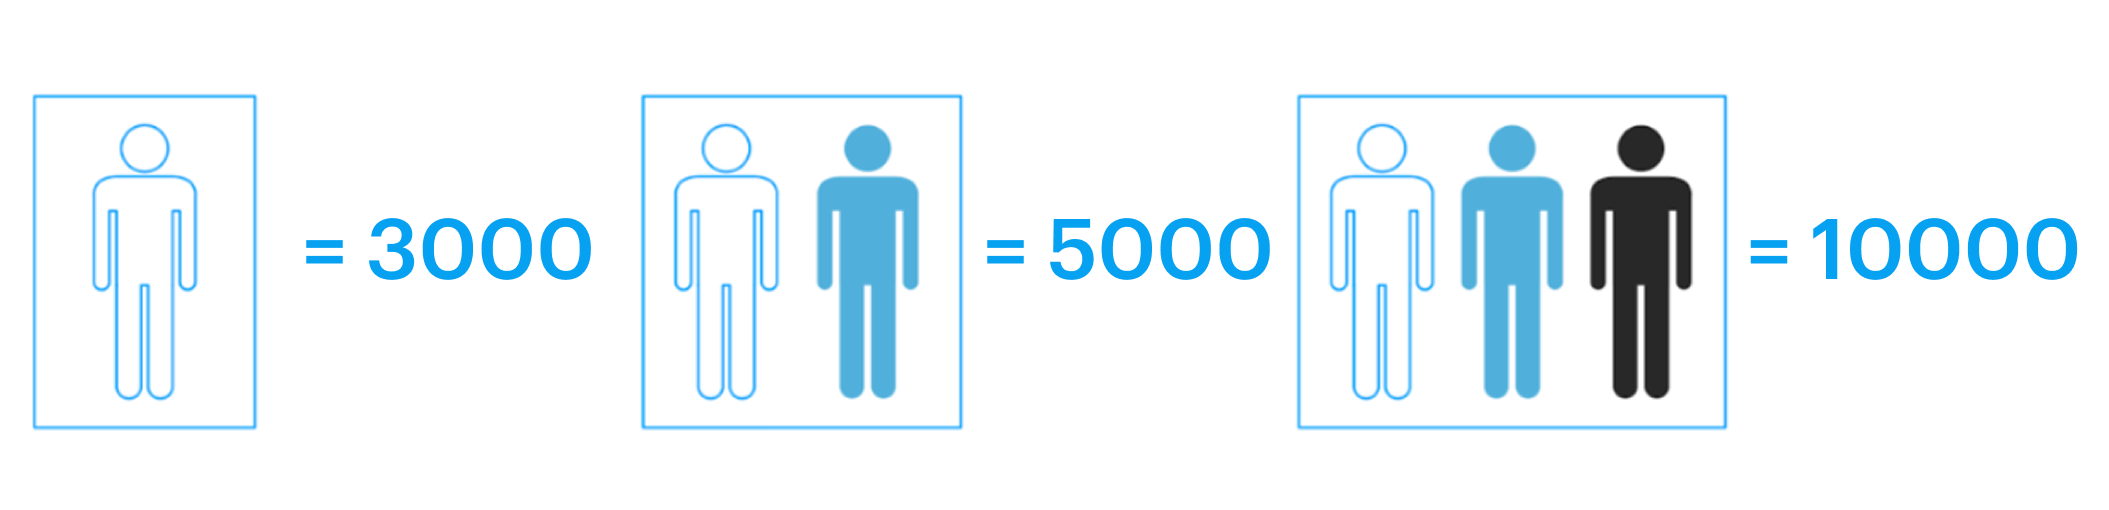

Этот метод очень чувствителен к порядку, в котором люди присоединяются к компании. Поэтому посчитаем эти цифры для всех возможных перестановок и усредним.

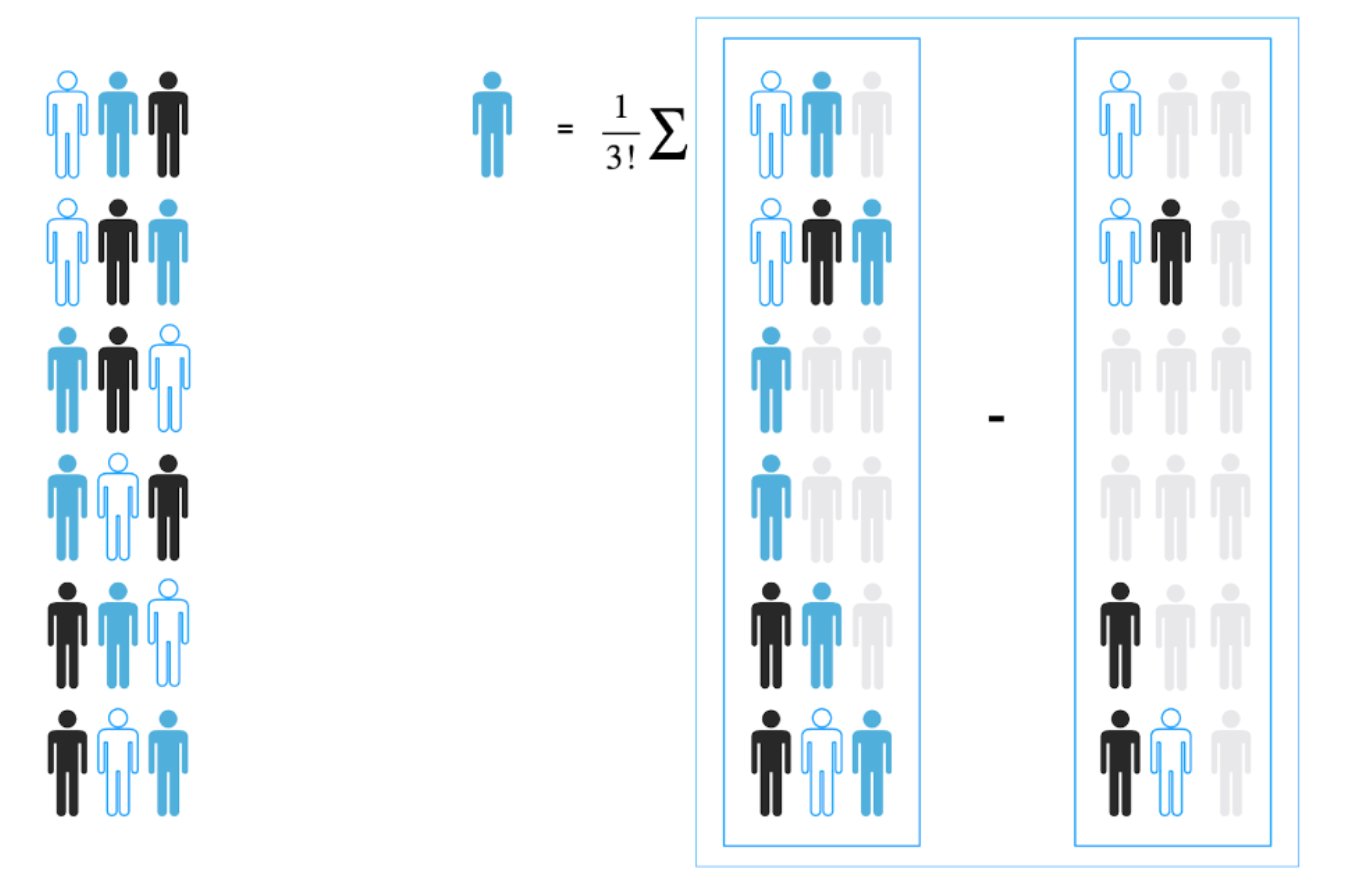

In [99]:
!pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.7/561.7 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.2/37.2 MB 1.0 MB/s eta 0:00:0000:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 1.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [shap]3/5 [numba]te]


In [100]:
import shap
from shap import Explainer, Explanation
from shap import waterfall_plot

In [101]:
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    n_jobs=-1,
    random_state=42,
)
rf_classifier.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [102]:
# Долго грузится
X_sample = X_train.sample(1000, random_state=0)

explainer = shap.TreeExplainer(rf_classifier)
shap_values = explainer(X_sample)

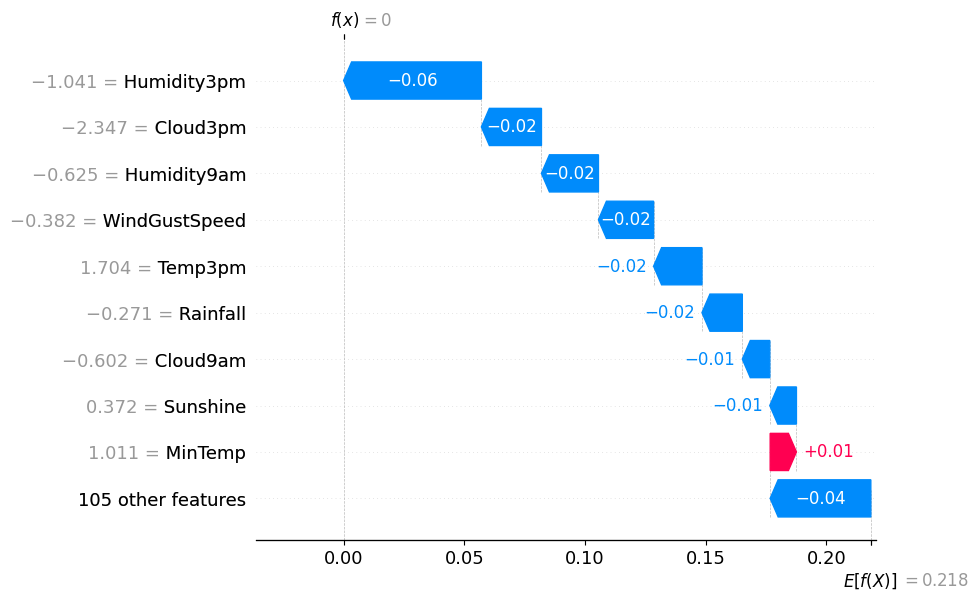

In [103]:
exp = Explanation(shap_values[:,:,1], shap_values.base_values[:,1], X_sample, feature_names=X_sample.columns)
idx = 7
waterfall_plot(exp[idx])

Диаграмма выше — это Waterfall-график.
Он показывает, как конкретные значения признаков повлияли на предсказание для одного наблюдения. От базового значения модели $E[f(X)]$ (среднего прогноза) шаги вправо (красные) повышают прогноз, а шаги влево (синие) понижают его.

Здесь, например, низкая `MinTemp`, низкая `WindGustSpeed` и высокая `Humidity3pm` снижают вероятность положительного класса, а высокая `Cloud3pm` и `Humidity9am` немного увеличивают её. Такой график полезен для локальной интерпретации — он объясняет, почему модель приняла решение именно для этого объекта.

Для анализа глобального эффекта функций используются результаты усреднения SHAP-значений.

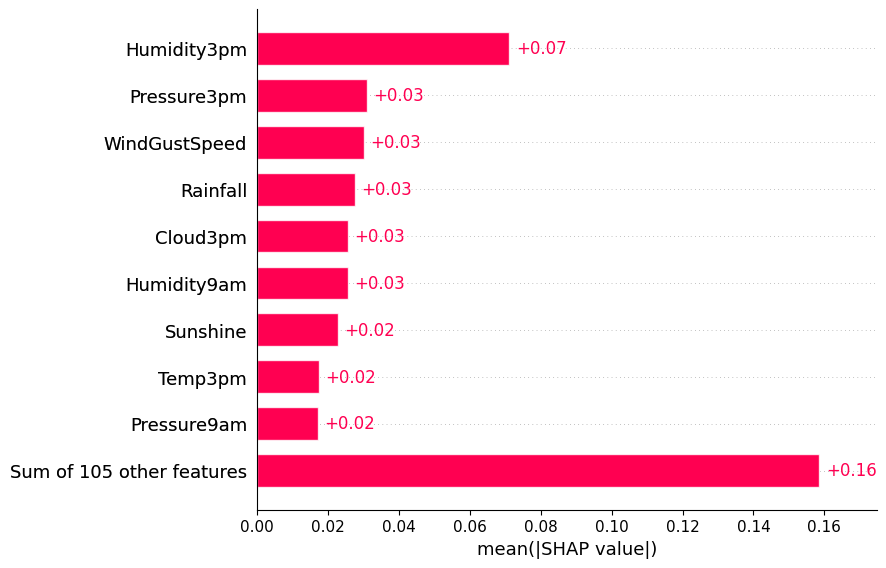

In [104]:
shap.plots.bar(shap_values[:,:,1])

Bar-график выше показывает усреднённую абсолютную важность признаков по всем наблюдениям, выраженную через средние |SHAPvalue|. Здесь `Humidity3pm` явно доминирует по влиянию, затем идут `Pressure3pm`, `WindGustSpeed`, `Rainfall`.

В отличие от MDI и MDA, SHAP даёт более стабильную оценку, так как учитывает влияние признака в контексте всех возможных комбинаций других признаков. MDI часто переоценивает признаки с большим количеством уникальных значений, а MDA может давать нестабильные оценки на коррелированных признаках — у SHAP эта проблема меньше выражена.

`shap.plots.beeswarm` помогает визуализировать все SHAP-значения для каждого признака. По оси $X$ этой диаграммы SHAP-значения сгруппированы по признакам. А цвет точек указывает на соответствующее значение признака. Обычно точки, цвет которых ближе к красному, указывают на более высокие значения признаков.

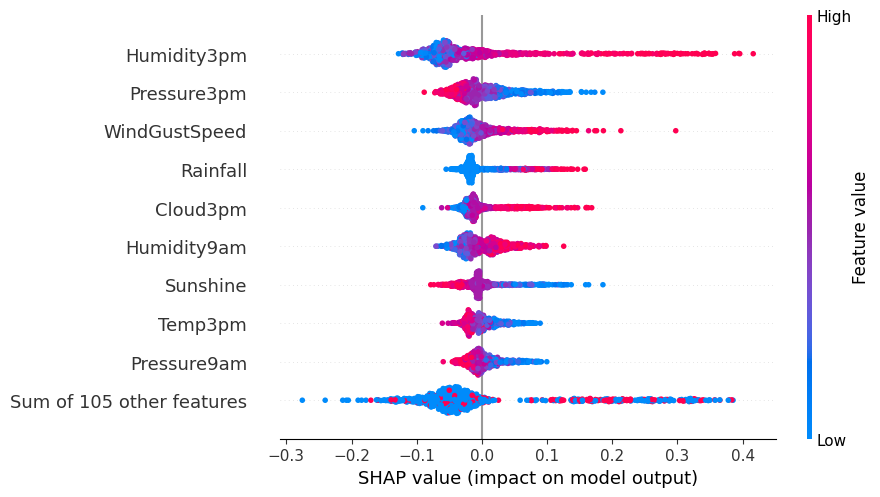

In [105]:
shap.plots.beeswarm(shap_values[:,:,1])

Beeswarm-график объединяет важность и распределение влияния признаков. Каждая точка — одно наблюдение, цвет отражает значение признака (синий — низкое, красный — высокое), положение по оси $X$ — эффект на предсказание. Например, высокая `Humidity3pm` (красные точки справа) сильно повышает прогноз, а низкая `Humidity3pm` (синие точки слева) понижает его. Этот график даёт как глобальную, так и частично локальную картину, чего нет у MDI и MDA.

**Сравнение SHAP с MDI и MDA**

- MDI (англ. Mean Decrease Impurity) и MDA (англ. Mean Decrease Accuracy) дают глобальные оценки важности, но чувствительны к мультиколлинеарности и масштабу признаков.

- SHAP оценивает влияние признаков через теорию кооперативных игр и анализирует вклад каждого признака в каждом прогнозе, поэтому интерпретация более прозрачная.

- В MDI и MDA `Humidity3pm` тоже был среди влиятельных признаков, но SHAP дополнительно показывает направленность эффекта и его распределение.

- MDA может распределить важность между коррелированными признаками, а SHAP чаще выделяет главный из них, сохраняя более логичную структуру.

### Extra Trees

> **Экстремально рандомизированные деревья** (англ. extremely randomized trees; Extra Trees) — усиленная версия случайного леса с ещё большим рандомизированием порогов разбиений.

Сравним обычный Random Forest и Extremely Randomized Trees. В Extra Trees сплиты выбираются более случайно (порог — случайный), что даёт меньшую дисперсию и часто схожее качество при повышенной скорости обучения.

In [106]:
from sklearn.ensemble import ExtraTreesClassifier

##### Задание 4 [1 балл]

- Запусти два ансамбля Random Forest и Extra Trees.

- На каждом шаге наращивай по 12 базисных деревьев, фиксируя ROC-AUC и время итерации. Это позволит увидеть динамику качества и скорости при увеличении `n_estimators` для RF и Extra Trees на одинаковых данных.

- Сеттинг: изначальное количество базисов = 12, деревья обучаются на бутстрэп-выборках в обоих ансамблях. Также используй `warm_start` для постепенного наращивания ансамблей.

- Изобрази зависимость ROC-AUC и времени обучения/предсказания обоих ансамблей от `n_estimators` на графике.

In [107]:
import time
from sklearn.metrics import roc_auc_score

roc_auc_scores_rf = []
train_predict_times_rf = []
roc_auc_scores_extra = []
train_predict_times_extra = []

n_steps = list(range(12, 192, 12))

rf = RandomForestClassifier(
    n_estimators=12,
    warm_start=True,
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced',
)
et = ExtraTreesClassifier(
    n_estimators=12,
    warm_start=True,
    bootstrap=True,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced',
)

for n in n_steps:
    rf.n_estimators = n
    t0 = time.perf_counter()
    rf.fit(X_train, y_train)
    t1 = time.perf_counter()
    proba = rf.predict_proba(X_test)[:, 1]
    t2 = time.perf_counter()
    roc_auc_scores_rf.append(roc_auc_score(y_test, proba))
    train_predict_times_rf.append((t1 - t0) + (t2 - t1))

    et.n_estimators = n
    t0 = time.perf_counter()
    et.fit(X_train, y_train)
    t1 = time.perf_counter()
    proba = et.predict_proba(X_test)[:, 1]
    t2 = time.perf_counter()
    roc_auc_scores_extra.append(roc_auc_score(y_test, proba))
    train_predict_times_extra.append((t1 - t0) + (t2 - t1))


/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:860: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(
/Users/ars-seliakin/miniconda3/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:860: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distribut

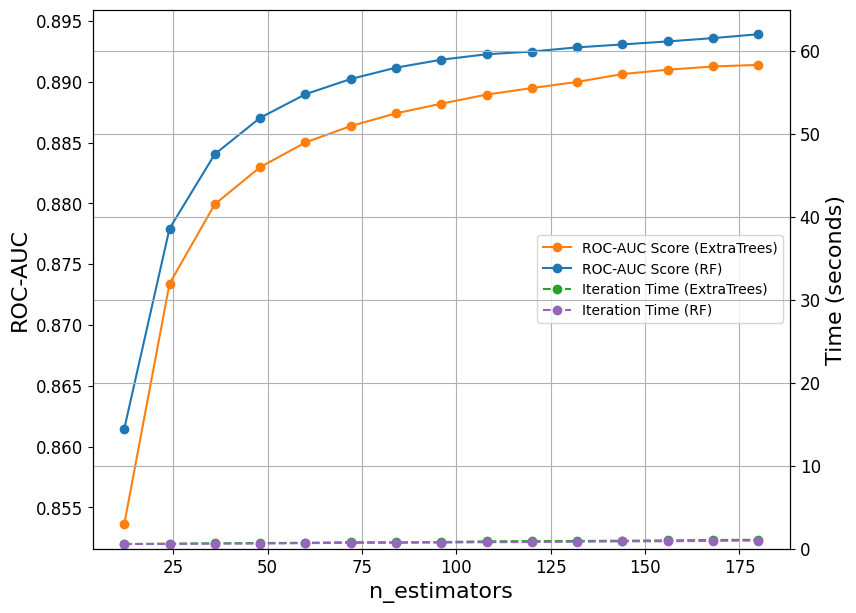

In [108]:
# Строим график
n_estimators_values = list(range(12, 192, 12))

plt.figure(figsize=(9, 7))

ax1 = plt.gca()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax1.plot(n_estimators_values, roc_auc_scores_extra, label='ROC-AUC Score (ExtraTrees)', marker='o', color='tab:orange')
ax1.plot(n_estimators_values, roc_auc_scores_rf, label='ROC-AUC Score (RF)', marker='o', color='tab:blue')
ax1.set_xlabel('n_estimators', fontsize=16)
ax1.set_ylabel('ROC-AUC', fontsize=16)
ax1.tick_params(axis='y')
plt.grid(axis='x')

ax2 = ax1.twinx()
plt.yticks(fontsize=12)

ax2.plot(n_estimators_values, train_predict_times_extra, label='Iteration Time (ExtraTrees)',
         linestyle='dashed', marker='o', color='tab:green')
ax2.plot(n_estimators_values, train_predict_times_rf, label='Iteration Time (RF)',
         linestyle='dashed', marker='o', color='tab:purple')

ax2.set_ylim(0, 65)

ax2.set_ylabel('Time (seconds)', fontsize=16)

ax2.tick_params(axis='y')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.grid()
plt.show()

### Cравнение Random Forest и Extra Trees

Random Forest использует случайное подмножество признаков при каждом сплите, но выбирает оптимальный сплит по критерию (например, Gini). Extra Trees, в отличие от него, выбирает порог сплита случайным образом, а не подбирает его оптимально. Это ускоряет обучение, но может немного снижать качество, особенно на сложных задачах с важными признаками и нелинейными зависимостями. В нашем графике RF стабильно показывает чуть более высокие ROC-AUC за счёт более «точных» разбиений.

Обычно Extra Trees обучается быстрее, так как не перебирает все возможные пороги для выбора наилучшего, а генерирует случайный порог. Однако в нашем случае разница во времени обучения между RF и ET минимальна. Это происходит потому, что число признаков и размер нашего датасета относительно велики. В сочетании с обучением очень глубоких деревьев это говорит о том, что основное время обучения тратится на построение самих деревьев, а не на поиск порогов. Более того, в нашем примере в Extra Trees мы использовали бутстрэп (по дефолту ET использует всю выборку). Это может ещё сильнее замедлять обучение ET.

В текущих условиях Random Forest даёт лучшее качество (ROC-AUC выше на всём диапазоне n_estimators), при этом скорость практически не уступает Extra Trees. Значит, для этой задачи RF предпочтительнее. Extra Trees можно использовать, когда скорость обучения важнее качества предсказаний и можно обучать ансамбль на обрезанных деревьях без применения бутстрэпа.

## Ключевые характеристики ансамблей

* **Бэггинг**
    * Плюсы:
        * Уменьшает дисперсию (variance).
        * Хорошо работает с нестабильными моделями (например, деревья).
        * Можно использовать OOB-оценку.
    * Минусы:
        * Не уменьшает смещение (bias).
        * Требует много вычислений при большом числе базовых моделей.
    * Где применяем:
        * Классификация и регрессия на данных с высокой дисперсией.
        * Хорошо заходит для нестабильных алгоритмов (решающие деревья).
* **Случайный лес**
    * Плюсы:
        * Автоматическое снижение корреляции между деревьями (рандомизация фич).
        * Надёжная модель out-of-the-box.
        * Может оценивать важность признаков.
    * Минусы:
        * Теряется интерпретируемость.
        * Может быть тяжёлым на больших данных.
        * Хуже работает на очень разрежённых данных.
    * Где применяем:
        * Классификация и регрессия на данных с высокой дисперсией.
        * Когда нужна стабильная модель с высоким показателем качества.
* **Изолированный лес** (Isolation Forest)
    * Плюсы:
        * Специализирован для поиска аномалий.
        * Хорошо работает с высокоразмерными данными.
        * Масштабируется на большие выборки.
    * Минусы:
        * Не для классической классификации/регрессии — только anomaly detection.
        * Требует аккуратного выбора гиперпараметров.
    * Где применяем:
        * Поиск выбросов в данных.
        * Этап препроцессинга данных.
        * Например, детекция мошенничества.
* **Extra Trees**
    * Плюсы:
        * Больше рандомизации, чем в Random Forest → ещё меньше variance.
        * Быстрее строятся (нет поиска оптимальных сплитов).
        * Иногда даёт даже лучшее качество.
    * Минусы:
        * Ещё меньше интерпретируемость, чем у RF.
        * Может сильнее переобучаться при малом числе деревьев.
    * Где применяем:
        * Большие табличные датасеты.
        * Когда нужно ускорение по сравнению с RF.

## Теперь ты умеешь


- Применять ансамблевые методы — бэггинг и случайный лес — с помощью инструментов библиотеки sklearn.
- Снижать дисперсию ML-моделей с помощью усреднения предсказаний.
- Подбирать и анализировать гиперпараметры, оценивая их влияние на качество и время обучения.
- Анализировать функции ROC-AUC и оценивать зависимость скорости работы от числа базовых моделей.
- Выбирать подход к оценке важности признаков (MDI, MDA).